# Which apartments are over-priced, and how sure are we? Location, photos, text and a trust layer on krisha.kz ads

**Course project, Final (Week 10 defence)** · Machine Learning Algorithms · Group **SE-2424**
**Team:** Rakhat Balgabekov, Aitbek Kaiyrbekuly
**Direction:** 1. Apartments for sale · **Task:** regression · **Target:** asking price (KZT) · **Data:** 4,815 krisha.kz ads (Astana, Almaty, October 2026) + 1,507 November ads as a temporal hold-out

This notebook continues the Endterm notebook on **the same cleaned data, the same 3,852 training ads, the same five folds and the same 963 saved test ads**. The Endterm model (tuned histogram gradient boosting on 24 structured fields) is the **base**; every Final block (location, photos, text) is added to it and kept only if it beats the base by more than the Endterm's one fold SD (0.354 M KZT) in 5-fold CV on duplicate-aware folds. The test ads are used once, in Section 8. Heavy computations (OSM downloads, image and text encoders, fine-tuning) run in the scripts named in each section and write to `outputs/`; the notebook reads those files and recomputes the cheap parts with the shared package `krisha_ml`. Every table and figure is followed by our reading of it.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "krisha_ml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from krisha_ml import core, raw  # noqa: E402  (the shared foundation: data, folds, model, metrics)

OUT = core.OUTPUT_DIR
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)


def _pending(rel):
    display(Markdown(f"> *Pending:* `outputs/{rel}` is not there yet (see the script named above)."))


def read_csv(rel, **kw):
    """Read outputs/<rel>; show a pending note and return None when the file is not there yet."""
    p = OUT / rel
    if not p.exists():
        _pending(rel)
        return None
    return pd.read_csv(p, **kw)


def read_json(rel):
    p = OUT / rel
    if not p.exists():
        _pending(rel)
        return None
    return json.loads(p.read_text(encoding="utf-8"))


def show_figure(rel, width=900):
    p = OUT / rel
    if not p.exists():
        _pending(rel)
        return False
    display(Image(filename=str(p), width=width))
    return True


def cv_view(t):
    """Every track's CV table in one format: mean ± fold SD, MdAPE, delta to the base, folds better, 1-SD rule."""
    if t is None or "cv_mae_M" not in t:
        return None
    v = pd.DataFrame({"variant": t.iloc[:, 0]})
    v["CV MAE (M KZT)"] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(t["cv_mae_M"], t.get("cv_mae_sd_M", 0 * t["cv_mae_M"]))]
    for src, dst, r in [("cv_mdape", "CV MdAPE %", 2), ("cv_r2", "CV R²", 3), ("delta_vs_base_M", "Δ vs base (M)", 3)]:
        if src in t:
            v[dst] = t[src].round(r)
    if "folds_better" in t:
        v["folds better"] = t["folds_better"].map(lambda x: f"{int(x)}/5" if pd.notna(x) else "")
    if "passes_1sd_rule" in t:
        v["kept (1-SD rule)"] = t["passes_1sd_rule"].astype(str).str.lower().map({"true": "yes", "false": "no"}).fillna("")
    return v.set_index("variant").sort_values("CV MAE (M KZT)")


def show_cv(rel):
    v = cv_view(read_csv(rel))
    if v is not None:
        display(v)
    return v


BASE = read_json("core/base_cv.json")
THRESHOLD = BASE["cv_mae_M"] - BASE["cv_mae_sd_M"] if BASE else None

## 1. The question, and what changed since the Endterm

The question is the Endterm's, now with the second half the Endterm could not answer:

> **Which apartments in Astana and Almaty are asked above or below what comparable apartments go for, by how much, and how sure can we be?**

A **buyer** wants to know whether an ad is worth a viewing; a **seller** wants a defensible starting price; a **realtor** wants a reference for every new listing. The Endterm gave them a point estimate (test MAE 6.29 M KZT, MdAPE 9.13 %) and a crude flag ("more than 20 % above the estimate"). Its own error analysis said where the remaining error lives: in what the 24 structured fields **do not contain**: the exact location beyond the district, the state of the flat that only the photos show, and the selling points written in the description. The Final therefore (1) checks first that the CV is honest (duplicate ads, Section 2), (2) adds three information sources the Endterm left unused (Sections 3–5), (3) keeps only what passes one fixed rule (Section 6), and (4) replaces the 20 % flag with calibrated price intervals, explanations and comparable ads (Section 7).

| | Endterm | Final |
|---|---|---|
| Data | 4,815 ads, 24 structured fields | + coordinates → OSM objects, + up to 5 photos per ad, + full description text, + 1,507 November ads |
| CV | KFold(5, shuffle, 42) | the same folds with every **duplicate group moved whole into one fold** (26 ads moved; primary scheme), random folds reported next to them |
| Model | tuned HGB on log price | the same HGB, 50/50 log-blended with a small **multimodal network** on location, raw fields, photo and text features (chosen by CV, Section 6) |
| Selection rule | lowest CV MAE | CV MAE better than the base by **> 0.354 M** (the Endterm fold SD, fixed): below **6.370 M** on the repaired folds (6.262 M on the random folds) |
| Output for the user | point estimate, > 20 % flag | estimate + **conformal 80/90 % interval**, SHAP reasons, 5 comparable ads, interval-based flag |
| Evaluation | 963 test ads once | the same 963 test ads once + **November temporal hold-out** |

In [2]:
# The base: the submitted Endterm model, reproduced by krisha_ml (scripts/verify_endterm.py)
repro = read_json("core/endterm_repro_test.json")
display(pd.DataFrame({
    "Endterm (submitted)": {k: core.ENDTERM_REFERENCE[k] for k in ["cv_mae_M", "cv_mae_sd_M", "cv_mdape", "cv_r2", "test_mae_M", "test_mdape", "test_r2"]},
    "krisha_ml reproduction": {**{k: BASE[k] for k in ["cv_mae_M", "cv_mae_sd_M", "cv_mdape", "cv_r2"]},
                               "test_mae_M": repro["test"]["mae_M"], "test_mdape": repro["test"]["mdape"], "test_r2": repro["test"]["r2"]},
}).round(4))
print(f"random (Endterm) folds: kept only if CV MAE < {THRESHOLD:.3f} M KZT (base {BASE['cv_mae_M']:.3f} - margin {BASE['cv_mae_sd_M']:.4f})")
SEL = read_json("final/selection.json")
if SEL:
    print(f"repaired (duplicate-aware) folds, the primary scheme: kept only if CV MAE < {SEL['rule_threshold_M']:.3f} M KZT "
          f"(base {SEL['base_cv_mae_M']:.3f} ± {SEL['base_cv_sd_M']:.3f} - fixed margin {SEL['rule_margin_M']:.4f})")

,Endterm (submitted),krisha_ml reproduction
cv_mae_M,6.616,6.616
cv_mae_sd_M,0.353,0.353
cv_mdape,8.934,8.934
cv_r2,0.857,0.857
test_mae_M,6.291,6.291
test_mdape,9.129,9.129
test_r2,0.855,0.855


random (Endterm) folds: kept only if CV MAE < 6.262 M KZT (base 6.616 - margin 0.3535)
repaired (duplicate-aware) folds, the primary scheme: kept only if CV MAE < 6.370 M KZT (base 6.723 ± 0.264 - fixed margin 0.3535)


**Reading.** The shared package reproduces the submitted Endterm to four decimals: CV MAE **6.616 ± 0.353 M KZT**, test MAE 6.29 M (the test number is shown only to prove the reproduction; it played no part in any choice below). Every number in Sections 2–7 is computed on the 3,852 training ads. The yardstick is strict on purpose: a block has to lower the CV MAE by more than **0.354 M**, the Endterm's fold SD. After the leakage audit (Section 2.2) the primary folds are the Endterm folds with every duplicate group in one fold; there the base scores 6.723 M and the threshold is **6.370 M**. The margin is kept at 0.354 M rather than the 0.264 M fold SD of the repaired folds, because the fold SD itself moves between 0.26 and 0.50 M with the fold seed; a smaller SD from one split would loosen the rule by chance (an earlier draft used 6.459 = 6.723 − 0.264, and the leakage review corrected it). With five folds, smaller gains cannot be told apart from the luck of the split.

## 2. Data and leakage audit

### 2.1 The data and the preprocessing pipeline
The pipeline is the Endterm's, packed into `krisha_ml.core` so that every track uses it unchanged: the cleaned table (`data/clean/krisha_apartments_clean.csv`, cleaning steps in the Midterm notebook), coordinates outside the city box set to missing (10 ads), 24 features (11 numeric, 10 categorical, 3 boolean), median imputation with missing-value indicators for numbers, one-hot encoding with a minimum frequency of 10 for categories, and the target on the log scale (`TransformedTargetRegressor`), so that the model minimises relative rather than absolute errors and predicts back in KZT. Anything fitted on data in the Final (TF-IDF vocabularies, PCA, probes, conformal quantiles) is fitted **inside each training fold** through `core.cv_evaluate(feature_fn=...)` or a residual corrector, never on all ads.

In [3]:
train = core.load_train()
print(f"training ads: {len(train.ids):,}; features: {len(core.FEATURES)}; test ads (kept aside): {len(core.load_test_ids()):,}")
display(train.df.groupby("city").agg(ads=("price", "size"), median_price_M=("price", lambda s: s.median() / 1e6),
                                      median_area=("area", "median"), with_coordinates=("lat", lambda s: s.notna().mean())).round(2))
display(pd.Series({"numeric": core.NUM, "categorical": core.CAT, "boolean": core.BOOL}).map(", ".join).to_frame("features"))

training ads: 3,852; features: 24; test ads (kept aside): 963


,ads,median_price_M,median_area,with_coordinates
city,,,,
Almaty,1849,43.5,61.0,1.00
Astana,2003,38.0,62.3,0.99


,features
numeric,"area, log_area, rooms, kitchen_area, floor, to..."
categorical,"city, district, building_type, condition, bath..."
boolean,"has_complex, mortgaged, is_urgent"


**Reading.** The two cities are almost balanced in the training rows, and nearly every ad has coordinates, which is what makes the location block of Section 3 possible. The feature list is exactly the Endterm's 24 columns; every new block below is an *addition* to it, so a change in the CV MAE can be attributed to that block alone.

### 2.2 Duplicate ads: is the Endterm CV honest?
A krisha.kz flat is often listed twice: reposted by the owner, or listed by the owner and an agency, with the same photos and nearly the same price. If one copy sits in a training fold and the other in the validation fold, the model can "remember" the price, and the CV MAE is optimistic. We looked for duplicates with four independent signals (`scripts/leakage_audit.py`, `krisha_ml.dedup`): perceptual hashes of the photos (pHash/dHash), cosine similarity of image embeddings, structured fields (area within 1 %, price within 5 %, within 150 m), and TF-IDF similarity of the descriptions. Photos shared by more than five ads (stock pictures of a residential complex) are ignored, because they connect different flats.

In [4]:
leak = read_json("leakage/leakage_summary.json")
if leak:
    rows = {k: leak[k] for k in ("all_links", "same_flat") if k in leak}
    display(pd.DataFrame(rows).T[["groups", "ads_in_groups", "groups_crossing_split", "test_ads_with_train_twin", "test_ads_with_train_twin_pct"]])
    display(pd.Series(leak["pairs_by_signal"], name="pairs").sort_values(ascending=False).to_frame())

,groups,ads_in_groups,groups_crossing_split,test_ads_with_train_twin,test_ads_with_train_twin_pct
all_links,43,90,13,13,1.35
same_flat,18,36,7,7,0.73


,pairs
phash+emb,28
struct,6
phash,6
text,2
phash+emb+struct+text,2
emb+struct+text,1
emb,1
struct+text,1
phash+emb+struct,1


**Reading.** The four signals find **48 duplicate pairs**, which merge into **43 groups** covering 90 ads (18 groups are certainly the same flat). Most pairs are found by the photos (pHash and embeddings agree), a few only by the structured fields or the text, which is why one signal alone would miss some. Only **13 test ads (1.35 %)** have a twin in the training rows: the saved test split is almost clean, and its number in Section 8 cannot be inflated by more than this small share. The cleaning step of the Midterm (same address, rooms, floor and area) caught the obvious reposts; what remains are reposts with a changed street spelling or price.

,description,cv_mae_mean,seed_sd,fold_sd_mean,mdape,r2,n_seeds,delta_vs_random_M
scheme,,,,,,,,
random,Random KFold (Endterm),6.720,0.058,0.371,8.960,0.847,20,0.000
random_dupfix,"Same KFold, duplicate groups kept together",6.734,0.064,0.367,8.955,0.846,20,0.015
dup,GroupKFold by duplicate group,6.724,0.081,0.372,8.922,0.847,10,0.004
building,GroupKFold by building (+dups),7.490,0.114,0.569,9.916,0.816,10,0.770
spatial1km,Spatial 1 km blocks (+dups),7.692,0.093,0.700,10.259,0.813,10,0.972
spatial3km,Spatial 3 km blocks (+dups),8.395,0.187,1.177,11.019,0.777,10,1.675
placebo,"Placebo: same KFold, 26 random non-duplicate a...",6.717,0.069,0.375,8.897,0.847,20,-0.003


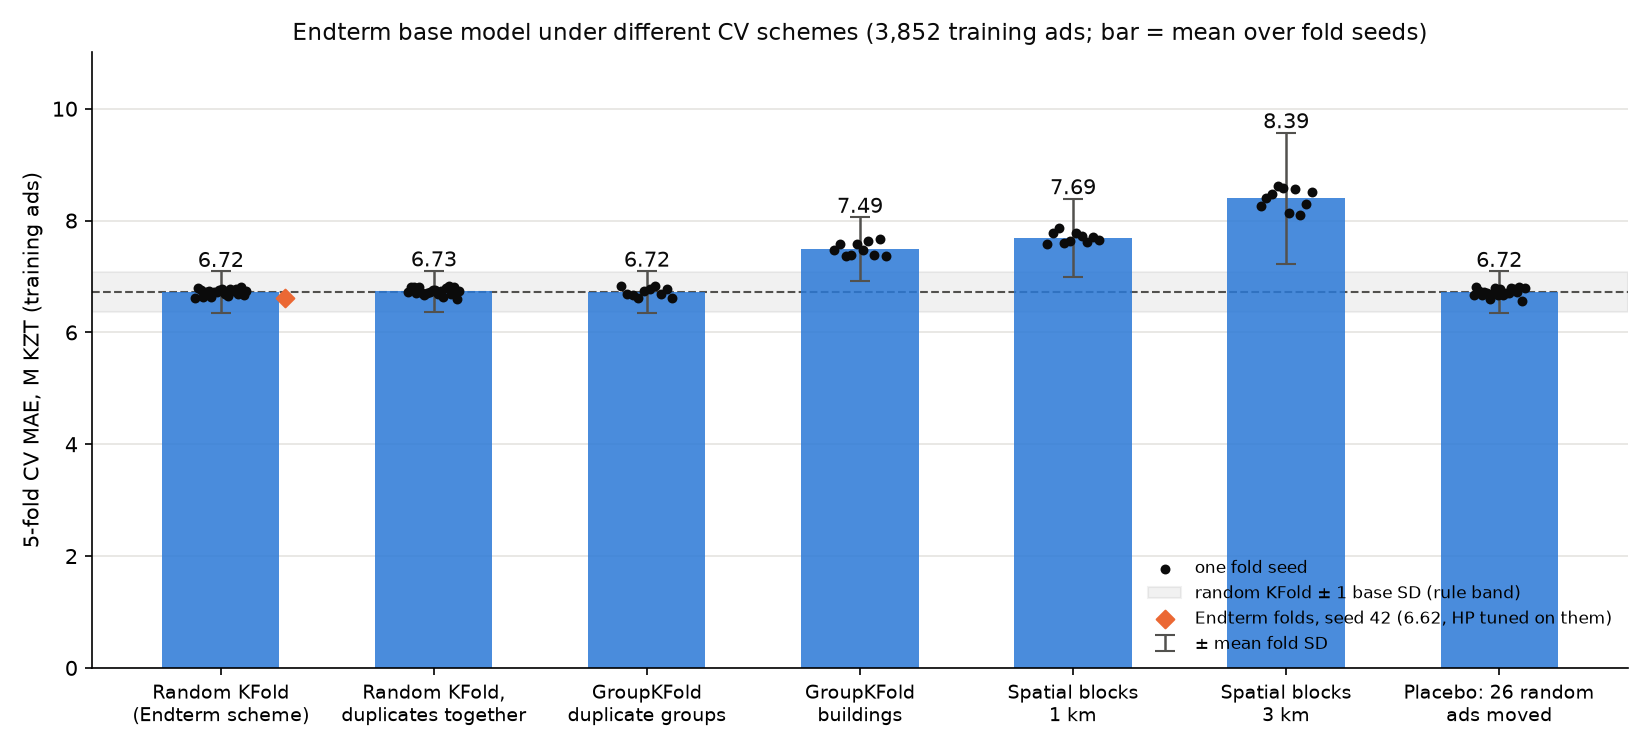

True

In [5]:
schemes = read_csv("leakage/cv_schemes_summary.csv", index_col=0)
if schemes is not None:
    display(schemes)
show_figure("leakage/cv_schemes.png")

**Reading.** The base model scored with folds that keep every duplicate group together (GroupKFold) gives **6.723 ± 0.264 M**, against 6.616 M for the Endterm's random folds. The difference is far smaller than one fold SD: duplicates are too few to change the Endterm's conclusions. Within the duplicate groups the effect is visible but small (ads whose twin sits in another fold: MAE 4.20 M with random folds, 5.60 M with repaired folds), because boosting on 24 fields does not memorise single ads the way a nearest-neighbour model would; simply copying the twin's price would have given a median error of 3.5 %. Over 20 fold seeds, keeping duplicates together costs only +0.015 ± 0.058 M (a placebo that moves 26 random ads: −0.003), so duplicate leakage is small; the Endterm's seed-42 folds are, however, the best of 20 seeds (6.616 against a 6.720 average), i.e. its CV is ~0.1 M optimistic because the hyper-parameters were tuned on them. The track tables of Sections 3–5 are on the Endterm folds (threshold 6.262 M); **the model choice of Section 6 uses the repaired folds** (`outputs/leakage/folds_group.csv`) as the primary scheme and reports the random folds next to them: a block that helps only by matching duplicates would gain more on the random folds than on the repaired ones.

## 3. Location features

**Concept.** Boosting already splits on latitude and longitude, but a tree sees coordinates only as two numbers and has to approximate "close to a park" or "far from the centre" with many axis-parallel cuts; with 3,852 ads it can only afford a few. We therefore compute what a buyer means by location, as features: the great-circle (haversine) distance to the city centre, the distance to the nearest park, school, kindergarten, supermarket, clinic and food place, and the number of such objects within 500 m and 1 km, from OpenStreetMap (Overpass API, downloaded once, cached in `cache/osm/`, `krisha_ml.geo`). Nearest-neighbour queries use a `BallTree` with the haversine metric. These are static, price-free features computed per ad, so they may go into `extra` without fold fitting. We also parse the raw ad-page fields the Endterm left unused (flooring, doors, furniture, internet, security; `features_rawfields.csv`).

In [6]:
geo_cv = show_cv("geo/cv.csv")
pois = read_csv("geo/osm_poi_summary.csv")
if pois is not None:
    display(pois)

,CV MAE (M KZT),CV MdAPE %,CV R²,Δ vs base (M),folds better,kept (1-SD rule)
variant,,,,,,
base + geo + raw fields,6.481 ± 0.280,8.53,0.862,-0.135,4/5,no
base + geo (OSM),6.531 ± 0.251,8.82,0.863,-0.085,3/5,no
base + distance to centre only,6.543 ± 0.243,8.67,0.861,-0.073,3/5,no
base (Endterm),6.616 ± 0.353,8.93,0.857,0.000,0/5,no
base + raw fields,6.766 ± 0.291,8.91,0.844,0.150,1/5,no


,city,layer,n_objects,n_points
0,Astana,park,184,2416
1,Almaty,park,307,4594
2,Astana,school,177,177
3,Almaty,school,363,363
4,Astana,kindergarten,148,148
5,Almaty,kindergarten,249,249
6,Astana,mall,58,58
7,Almaty,mall,80,80
8,Astana,supermarket,172,172
9,Almaty,supermarket,296,296


**Reading.** The best location variant, **base + geo + raw fields**, scores **6.481 ± 0.280 M**, -0.135 M against the base, better on 4 of 5 folds; 0 of 4 variants pass the 1-SD rule. The single feature "distance to the centre" (6.543 M) already gives most of the gain of the full OSM block (6.531 M): what the coordinates lacked was a *smooth* distance, not more objects. The raw ad-page fields on their own make the model slightly worse (6.766 M): 16 sparse columns, each filled in only half of the ads, add more noise than signal. The fold SD of the location variants is smaller than the base's, i.e. they help most on the fold where the base was worst, which is a hint of real signal even where the mean gain is under the threshold.

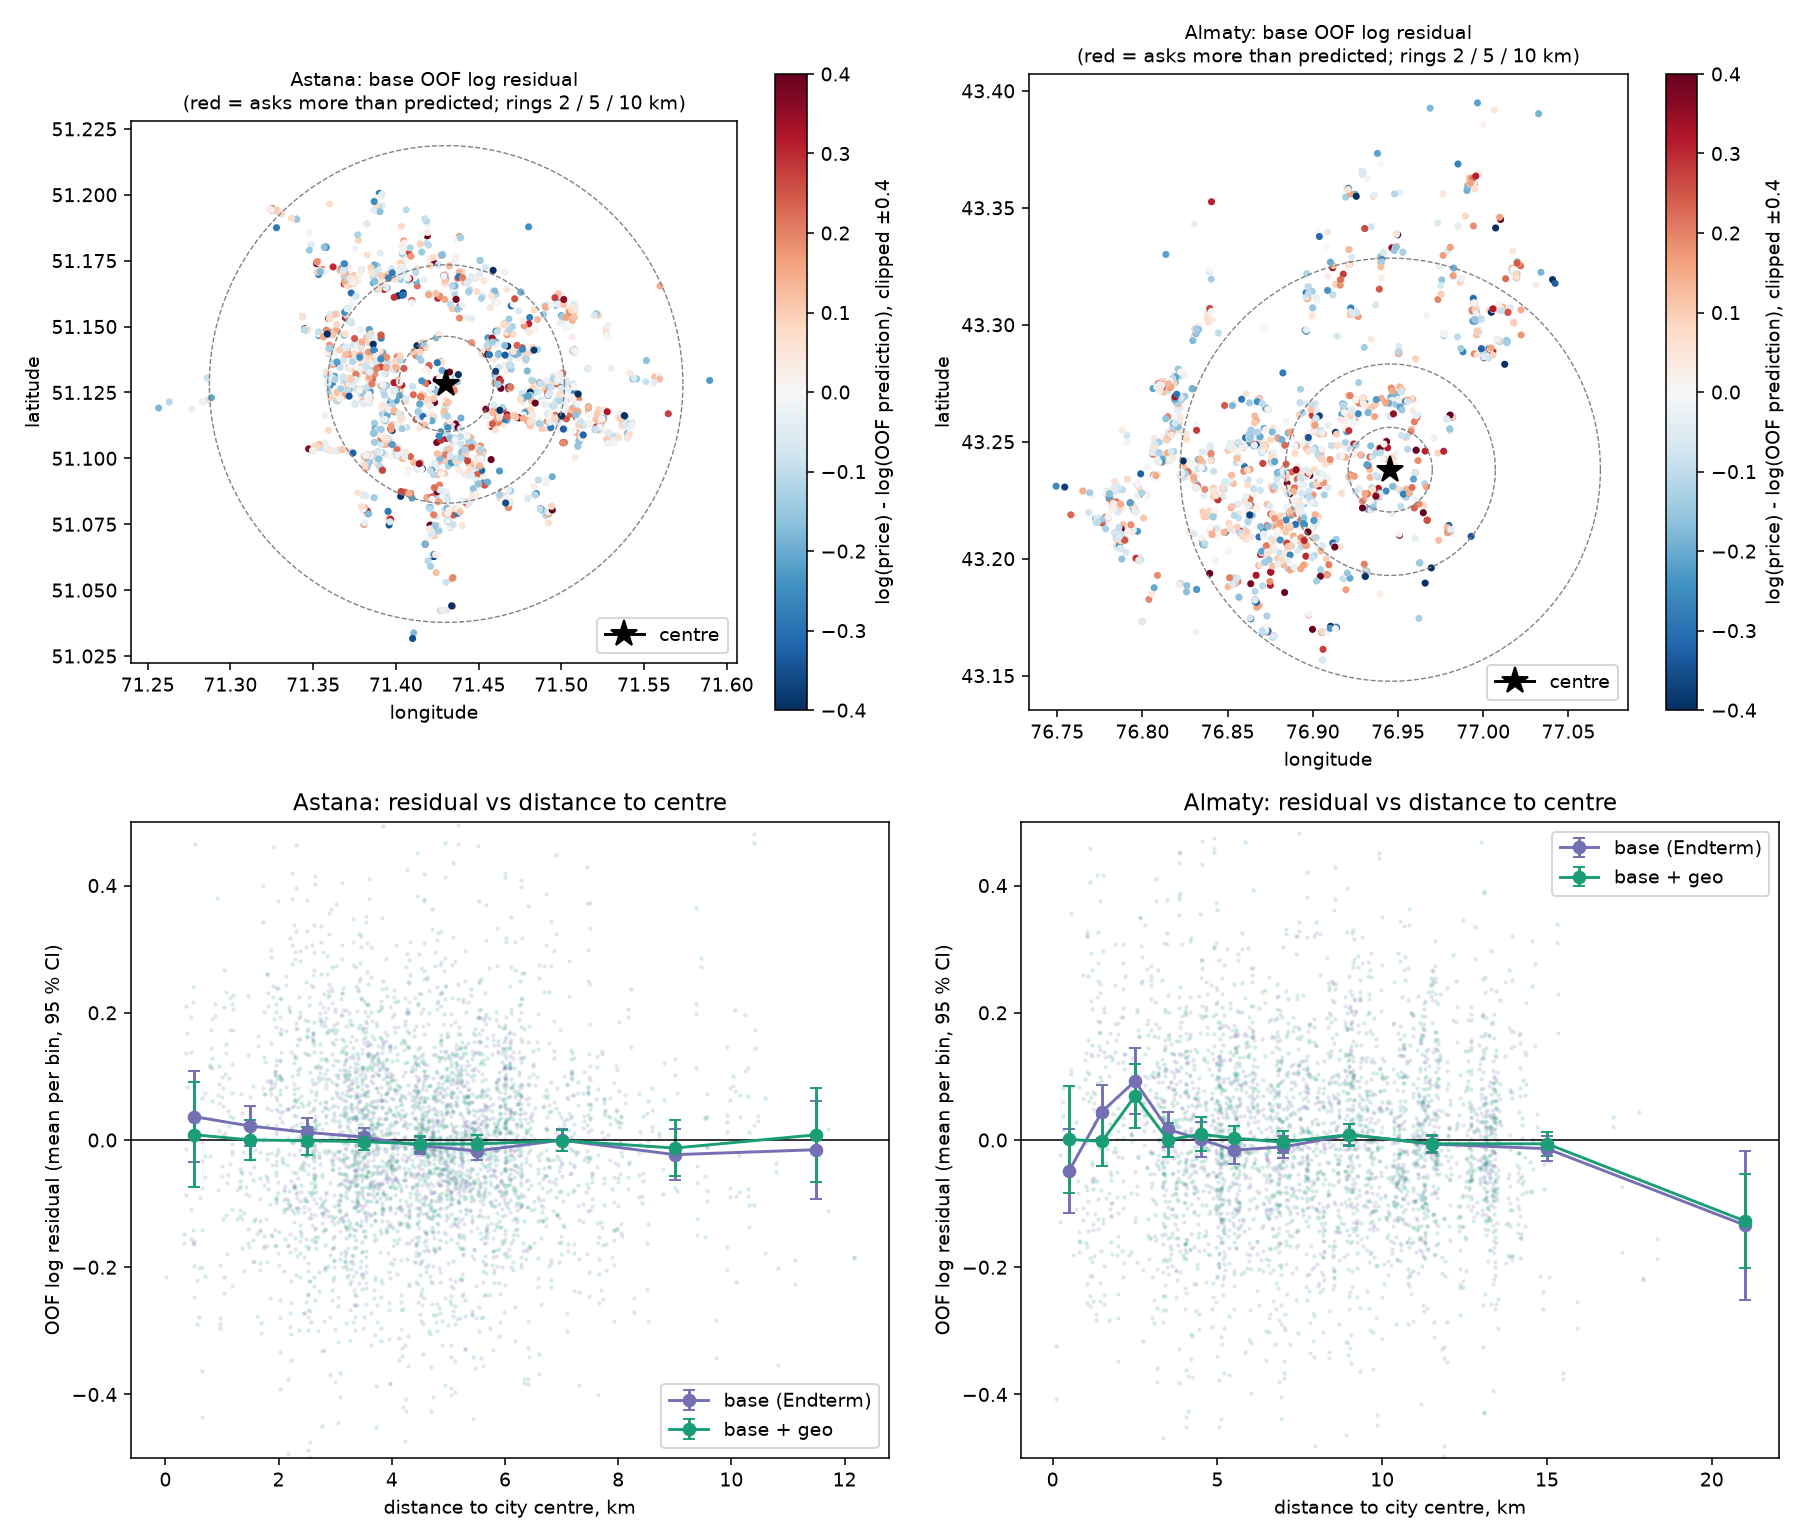

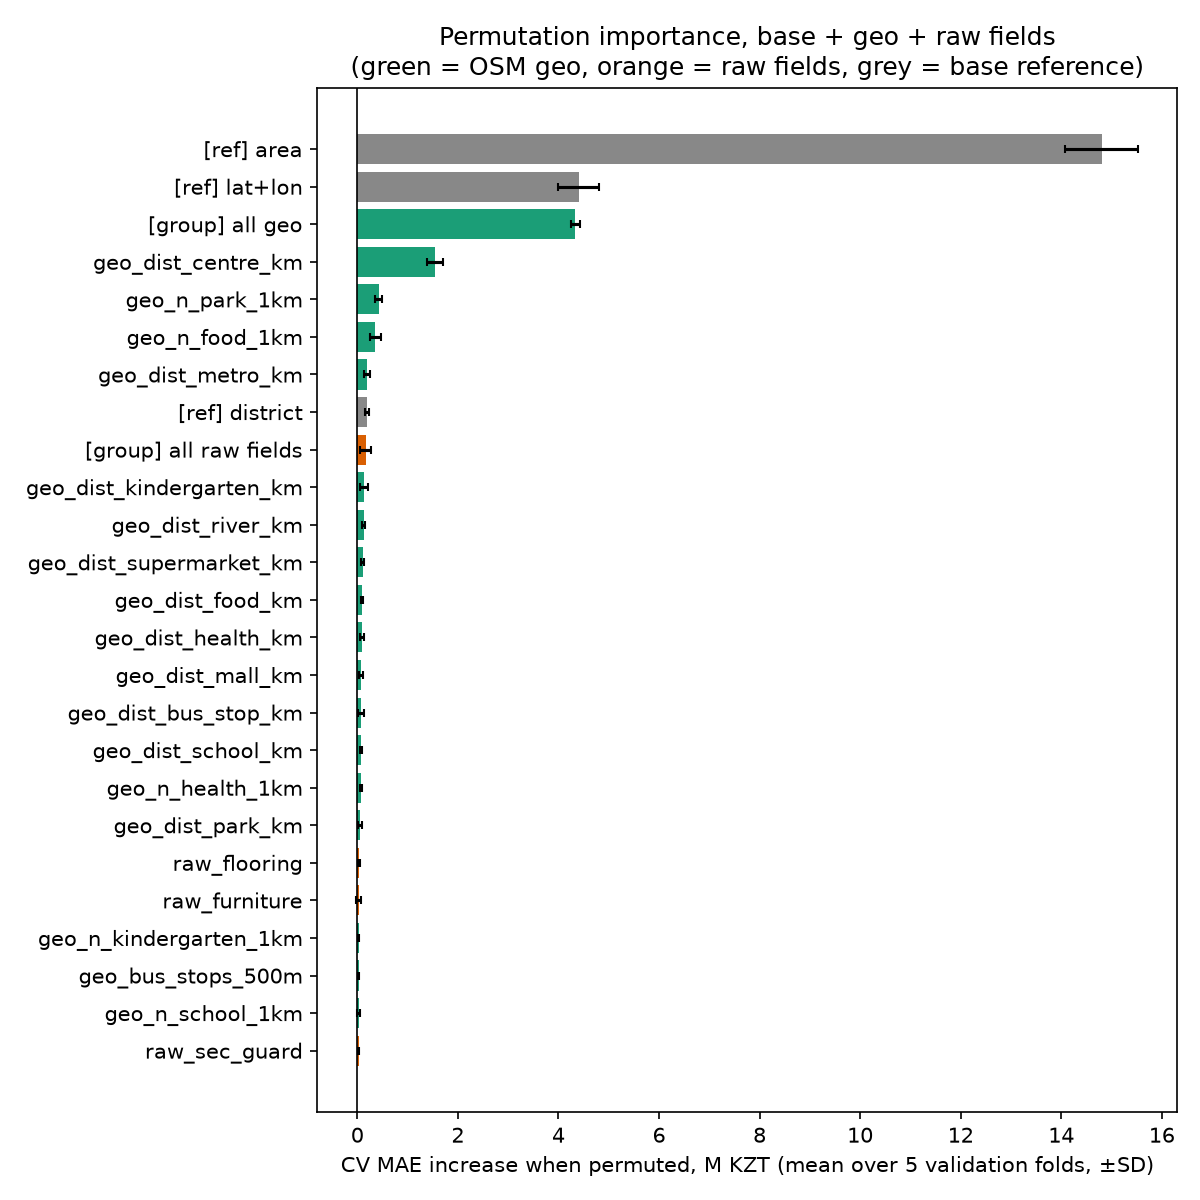

True

In [7]:
show_figure("geo/residual_map.png")
show_figure("geo/permutation_importance.png", width=700)

**Reading.** The residual map of the base model shows where the Endterm was wrong by location: patches of one colour (a prestige street, a district edge) are what a location feature can remove; scattered colours mean the remaining error is about the flat, not about the place. The permutation importance of the location model says which new columns it uses: shuffling the distance to the centre raises the CV MAE by 1.54 M, far more than any other OSM column (parks within 1 km: 0.42 M, food places within 1 km: 0.36 M), and all geo columns together by 4.34 M, about as much as latitude + longitude (4.40 M): the trees can rebuild most of the location from either, which is why the block adds little on top of the coordinates.

## 4. Photos: CLIP, a fine-tuned CNN, Grad-CAM and a mismatch flag

**Concepts.** A convolutional network (CNN) turns an image into a vector of learned features; ImageNet-pretrained networks (MobileNetV3, EfficientNet-B0) already recognise textures and objects, so with ~3,000 labelled ads we can either **freeze** them and train a logistic regression on top (a *linear probe*), or **fine-tune** the last layers with data augmentation. **CLIP** (contrastive language–image pre-training) maps images and sentences into the same space, which allows **zero-shot** classification by comparing a photo with prompts such as "a kitchen with designer renovation" or "an unfinished apartment with bare concrete walls", without any training. **Grad-CAM** weights the last convolutional feature maps by the gradient of the predicted class to show *where* the network looked.

**The task for the photos.** Price is a weak and noisy label for a picture, so we first teach the photos something they can see: the **condition of the flat** (fresh renovation, good, needs repair, shell/pre-finish), which the seller states in a field. All photo models are evaluated with folds that keep duplicate-photo clusters together (StratifiedGroupKFold), because a reposted ad with the same photos would otherwise appear on both sides. Scripts: `photo_01_embed.py` (embeddings, CLIP zero-shot), `photo_02_classify.py` (probes, fine-tuning), `photo_03_price.py` (photo features in the price model); module `krisha_ml.photos`. Photos stay local (`data/photos/`) and are never committed.

In [8]:
zs = read_csv("photos/clip_zero_shot_ad.csv")
if zs is not None:
    print(f"ads with at least one usable photo: {len(zs):,}")
    rooms = [c for c in zs if c.startswith("clip_share_")]
    display(zs[rooms].mean().sort_values(ascending=False).rename("mean share of photos").to_frame().round(3))
    cond = core.load_clean()[["id", "condition"]].merge(zs[["id", "clip_quality_index"]], on="id")
    display(cond.groupby("condition")["clip_quality_index"].describe()[["count", "mean", "50%"]].round(3))

ads with at least one usable photo: 4,574


,mean share of photos
clip_share_living_room,0.271
clip_share_corridor,0.198
clip_share_bedroom,0.173
clip_share_kitchen,0.155
clip_share_exterior,0.094
clip_share_bathroom,0.044
clip_share_floor_plan,0.043
clip_share_window_view,0.022


,count,mean,50%
condition,,,
free_layout,76.0,-0.698,-1.247
fresh_renovation,1372.0,0.922,1.108
good,814.0,0.176,0.155
needs_repair,100.0,-0.693,-0.996
rough,457.0,-0.406,-1.071
unknown,1755.0,0.418,0.618


**Reading.** CLIP zero-shot sorts the photos into rooms without a single label: living rooms (27 % of the photos), corridors (20 %), bedrooms (17 %) and kitchens (16 %) dominate; 9 % are exteriors and about 7 % floor plans, bathrooms or window views. Exteriors and plans say nothing about the condition of the flat, which is why the "interior-weighted" variants below down-weight them. The CLIP quality index (prompt probabilities from "designer renovation" to "bare concrete") is highest for ads stated as fresh renovation (mean 0.92), then good (0.18), and negative for rough finish (−0.41), needs repair (−0.69) and free layout (−0.70): zero-shot CLIP already separates renovated from unfinished flats, although it does not separate "needs repair" from "shell".

,C,macro_f1_cv,macro_f1_sd,accuracy_cv,balanced_acc,macro_f1_fold0,accuracy_fold0
model,,,,,,,
(a) frozen mnv3 + LR,0.003,0.592,0.028,0.678,0.622,0.552,0.656
(a) frozen effnet_b0 + LR,0.003,0.608,0.029,0.697,0.625,0.588,0.689
(c) CLIP linear probe,0.010,0.632,0.016,0.721,0.657,0.642,0.727
(c) CLIP linear probe [interior-weighted],0.003,0.638,0.016,0.723,0.667,0.622,0.709
(a) frozen effnet_b0 + LR [interior-weighted],0.003,0.613,0.032,0.699,0.623,0.584,0.678
(b) fine-tuned EfficientNet-B0,NaN,NaN,NaN,NaN,0.586,0.546,0.616
"(b) fine-tuned EfficientNet-B0 (lr 0.0002, interior photos only)",NaN,NaN,NaN,NaN,0.598,0.577,0.680


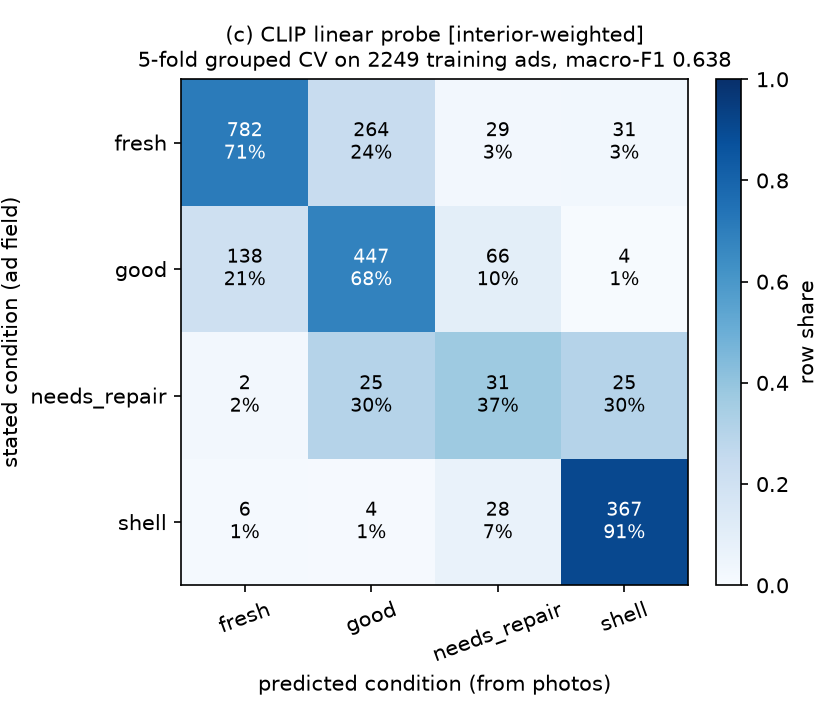

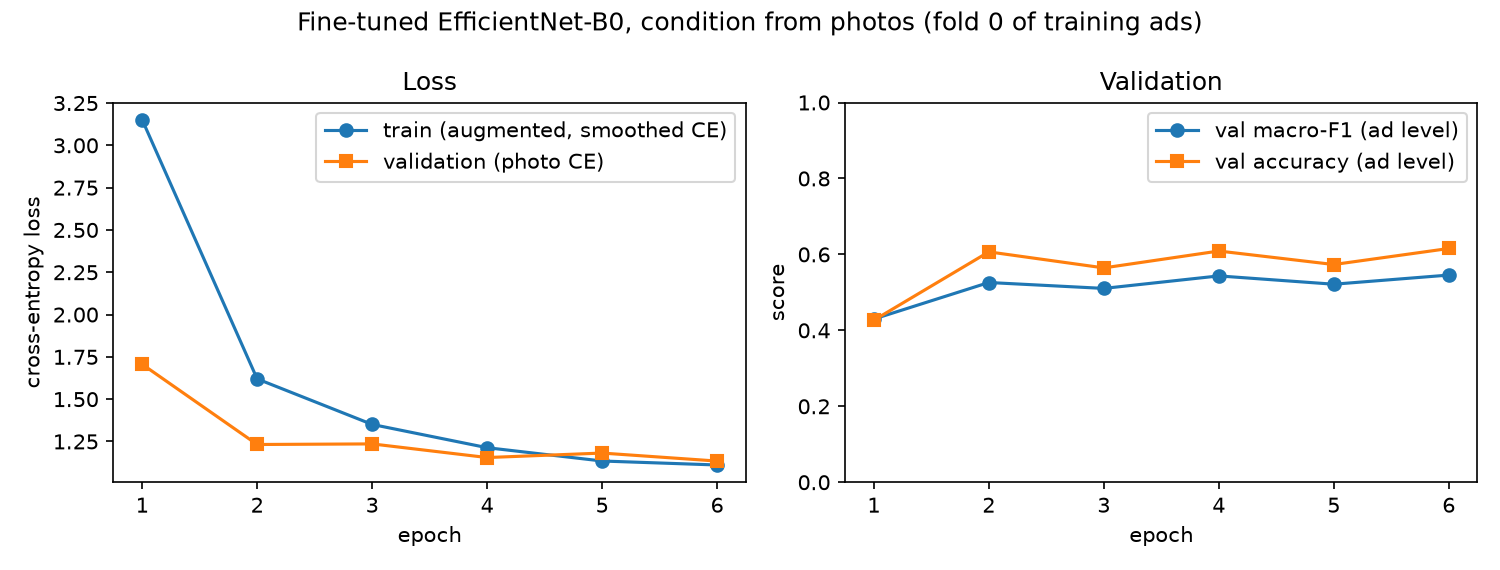

True

In [9]:
clf = read_csv("photos/classifier_comparison.csv")
if clf is not None:
    display(clf.set_index("model")[[c for c in ["C", "macro_f1_cv", "macro_f1_sd", "accuracy_cv", "balanced_acc", "macro_f1_fold0", "accuracy_fold0"] if c in clf]].round(3))
show_figure("photos/confusion_best_probe.png", width=520)
show_figure("photos/training_curves.png", width=760)

**Reading.** On 2,249 labelled training ads, the best model is **(c) CLIP linear probe [interior-weighted]**: macro-F1 0.632 for the CLIP linear probe against 0.592 for frozen MobileNetV3 and 0.608 for frozen EfficientNet-B0. The fine-tuned EfficientNet-B0 reaches macro-F1 0.546 on fold 0 (compare with the probes' fold-0 column, not with their 5-fold mean). CLIP wins because it was pre-trained on hundreds of millions of image–text pairs that include interior photos and words like "renovation", while ImageNet classes say nothing about wallpaper; fine-tuning a CNN on ~3,000 ads with noisy labels improves the training loss much faster than the validation loss (the curves), i.e. it overfits despite augmentation. The confusion matrix shows where the errors are: neighbouring classes (fresh vs good, needs repair vs shell) are confused, opposite ends almost never, so the classifier is ordinal in practice, and part of the confusion is in the labels themselves (sellers call a flat "fresh renovation" generously).

In [10]:
# Grad-CAM on the fine-tuned EfficientNet-B0 (fold 0 weights saved by photo_02_classify.py).
# The panels show krisha.kz photos, so they stay local (gitignored, data card: photos are never committed)
# and are not embedded in this notebook; set FINAL_SHOW_PHOTOS=1 to display them on a machine that has them.
import os
for f in ("photos/gradcam_correct.png", "photos/gradcam_incorrect.png"):
    if os.environ.get("FINAL_SHOW_PHOTOS") == "1":
        show_figure(f, width=900)
    else:
        print(f"outputs/{f}: local only (shows krisha.kz photos), "
              f"{'present' if (ROOT / 'outputs' / f).exists() else 'missing'}; rebuild with scripts/photo_05_gradcam.py")

outputs/photos/gradcam_correct.png: local only (shows krisha.kz photos), present; rebuild with scripts/photo_05_gradcam.py
outputs/photos/gradcam_incorrect.png: local only (shows krisha.kz photos), present; rebuild with scripts/photo_05_gradcam.py


**Reading.** The two Grad-CAM panels (kept local and not embedded here, because they show the sellers' photos) show where the fine-tuned EfficientNet-B0 looked, for correctly (top) and wrongly (bottom) classified photos. The heat maps are a sanity check, not a proof: they tell whether the network relies on the room surfaces that carry the label (walls, floors, finishing) or on objects that only correlate with it (furniture, a window view). Because the label belongs to the flat while one photo may not show the parts that decide it, the ad-level prediction averages over up to five photos.

In [11]:
# Mismatch flag: the photos contradict the stated condition
mm = read_csv("photos/mismatch_examples.csv")
mms = read_json("photos/mismatch_summary.json")
if mms:
    display(pd.DataFrame(mms["counts"]).T)
if mm is None and zs is not None:   # cheap fallback from CLIP zero-shot only, clearly labelled as such
    d = core.load_clean()[["id", "condition", "price"]].merge(zs, on="id")
    bad = d["clip_mean_needs_repair"] + d["clip_mean_shell"] + d["clip_mean_prefinish"]
    d["mismatch"] = (d["condition"].eq("fresh_renovation") & (bad > 0.5)) | (d["condition"].isin(["needs_repair"]) & (d["clip_mean_designer"] > 0.6))
    print("fallback (CLIP zero-shot, not the trained probe):")
    display(d.groupby("condition")["mismatch"].agg(["sum", "mean"]).round(3))
elif mm is not None:
    display(mm.head(10))

,none,photos_poor_vs_stated_good,photos_good_vs_stated_poor
train,3770,62,20
test,949,9,5


,id,split,stated_class,photo_class,mismatch,mismatch_conf,mismatch_reliable,photo_p_fresh,photo_p_good,photo_p_needs_repair,photo_p_shell,clip_mean_shell,clip_mean_modern,clip_interior_share,n_photos_ok,url
0,1014035697,train,needs_repair,fresh,photos_good_vs_stated_poor,0.996,1,0.941,0.055,0.002,0.002,0.002,0.635,1.0,5,https://krisha.kz/a/show/1014035697
1,1009548022,train,shell,fresh,photos_good_vs_stated_poor,0.992,1,0.930,0.063,0.007,0.000,0.001,0.281,1.0,5,https://krisha.kz/a/show/1009548022
2,1014494992,test,fresh,shell,photos_poor_vs_stated_good,0.992,0,0.007,0.001,0.139,0.853,0.761,0.111,0.0,5,https://krisha.kz/a/show/1014494992
3,1012019188,test,shell,fresh,photos_good_vs_stated_poor,0.990,1,0.914,0.077,0.006,0.004,0.000,0.154,1.0,5,https://krisha.kz/a/show/1012019188
4,1016261646,train,fresh,shell,photos_poor_vs_stated_good,0.988,0,0.006,0.006,0.085,0.903,0.543,0.196,0.0,1,https://krisha.kz/a/show/1016261646
5,1013110518,train,fresh,shell,photos_poor_vs_stated_good,0.988,1,0.008,0.004,0.126,0.862,0.847,0.000,1.0,5,https://krisha.kz/a/show/1013110518
6,1013795319,test,fresh,shell,photos_poor_vs_stated_good,0.986,0,0.013,0.000,0.146,0.840,0.959,0.031,0.0,5,https://krisha.kz/a/show/1013795319
7,1010899323,train,fresh,shell,photos_poor_vs_stated_good,0.986,0,0.010,0.004,0.167,0.818,0.939,0.008,0.0,5,https://krisha.kz/a/show/1010899323
8,1015620941,train,fresh,shell,photos_poor_vs_stated_good,0.981,1,0.018,0.001,0.052,0.929,0.033,0.039,0.4,5,https://krisha.kz/a/show/1015620941
9,1014414777,train,fresh,shell,photos_poor_vs_stated_good,0.972,0,0.018,0.010,0.102,0.870,0.943,0.047,0.0,5,https://krisha.kz/a/show/1014414777


**Reading.** The mismatch flag marks ads whose photos contradict the stated condition, e.g. "fresh renovation" in the field and bare walls in the pictures: 62 training ads look worse than stated and 20 look better (about 2 % of the training ads; 47 + 19 with a confident probe). For a buyer this is a question to ask before a viewing; for the model it is a hint that the stated `condition` field is noisy, which limits what any condition feature can add. It is a flag for a human, not an accusation: dark photos, a single exterior shot or a staged photo of a show flat cause false alarms.

,CV MAE (M KZT),CV MdAPE %,CV R²,Δ vs base (M),folds better,kept (1-SD rule)
variant,,,,,,
residual: HGB on condition probs + zero-shot,6.426 ± 0.440,8.66,0.868,-0.190,4/5,no
residual: RidgeCV on CLIP ad embedding,6.437 ± 0.385,8.83,0.869,-0.179,5/5,no
residual: RidgeCV on CLIP interior-weighted embedding,6.441 ± 0.391,8.77,0.868,-0.174,5/5,no
condition probs only where condition is not stated,6.500 ± 0.221,8.65,0.860,-0.116,4/5,no
residual: RidgeCV on legacy MobileNetV3 embedding,6.517 ± 0.389,8.85,0.863,-0.099,5/5,no
"Endterm base (tuned HGB, 24 features)",6.616 ± 0.353,8.93,0.857,NaN,,
photo condition probabilities (nested OOF probe),6.617 ± 0.298,8.43,0.849,0.001,3/5,no
condition probs + stated condition filled from photos,6.655 ± 0.336,8.69,0.848,0.039,1/5,no
CLIP embedding PCA(16),6.707 ± 0.408,8.83,0.849,0.091,2/5,no


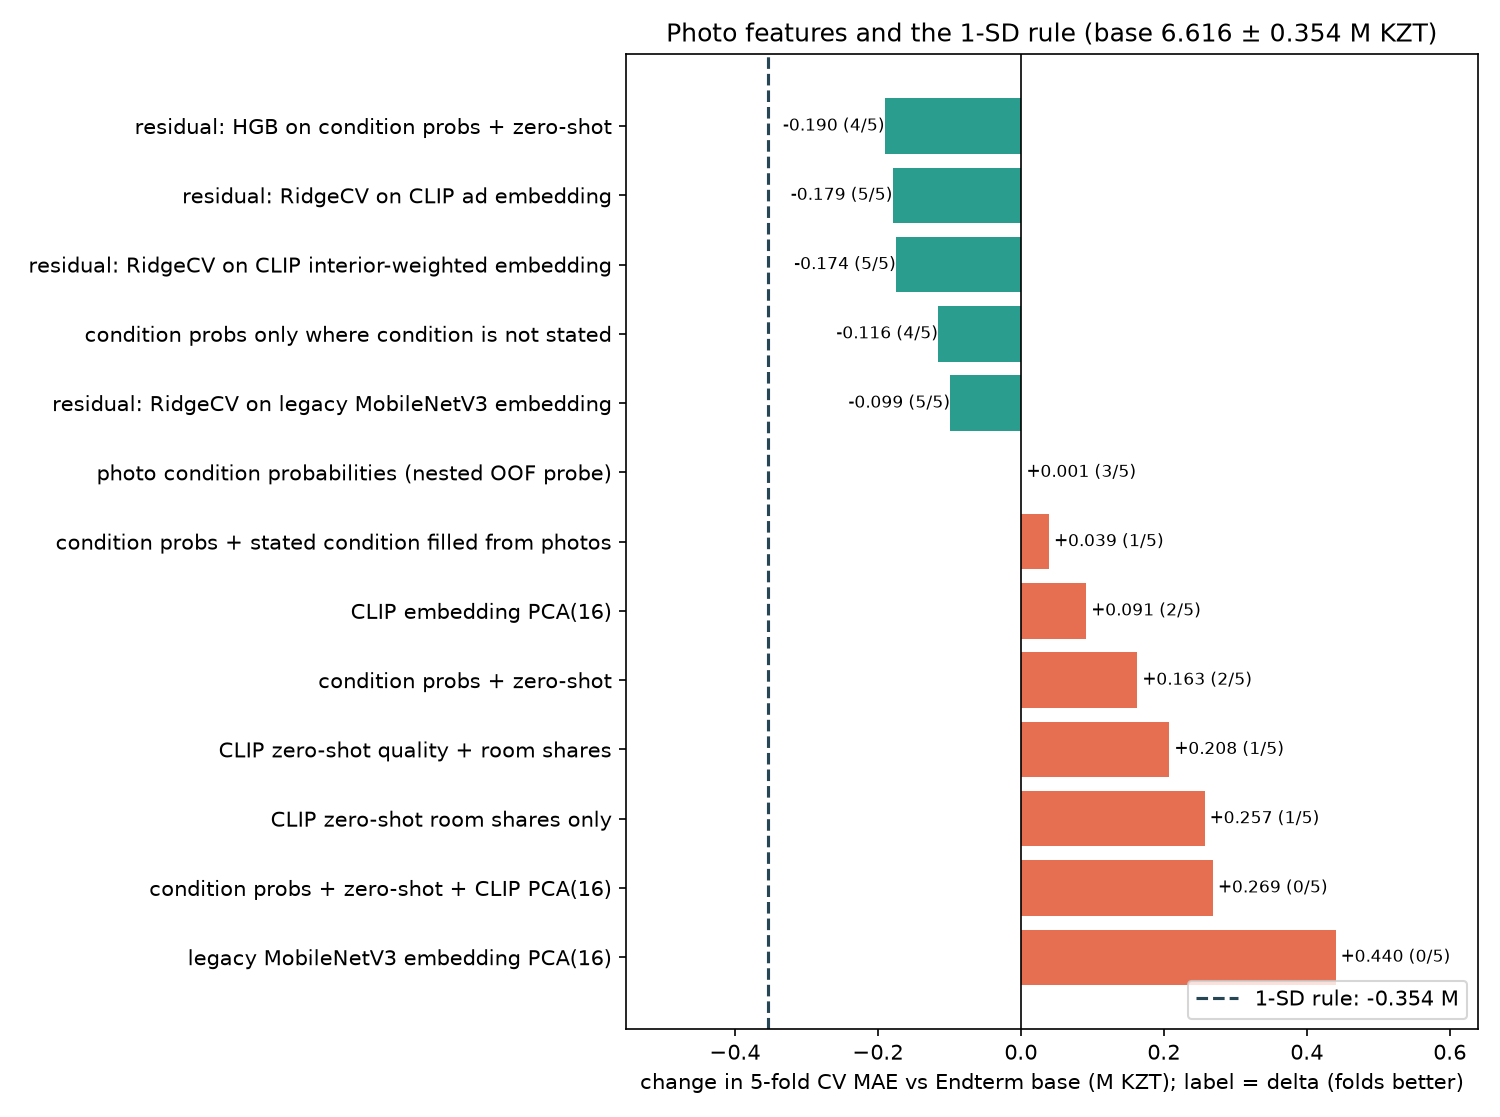

True

In [12]:
show_cv("photos/price_cv.csv")
show_figure("photos/price_cv_delta.png", width=760)

**Reading.** In the price model the photos help less than in the condition task: the best photo variant, **residual: HGB on condition probs + zero-shot**, scores 6.426 ± 0.440 M (-0.190 M, 4.00 of 5 folds better), and 0 of 14 variants pass the rule. The reason is that the base model already has the stated `condition`, building year and building type, which carry most of what a photo says about price; a photo adds the *degree* of renovation within a class, which matters for some ads and not for most. Raw embedding components as features do worse than a few interpretable probabilities, because 16 noisy PCA columns give the trees more ways to overfit.

## 5. Text: TF-IDF against transformers, and red flags

**Concepts.** **TF-IDF** represents a description as a sparse vector of word and character n-gram counts, weighted down for words that occur in every ad; with **Ridge** regression (L2 penalty, chosen by generalised cross-validation inside each training fold) it learns one weight per n-gram. A **transformer** sentence encoder (rubert-tiny2, multilingual USER-base) maps the whole text to a dense vector that captures meaning rather than exact words; we use it frozen (embedding + Ridge) and fine-tuned on the residuals. Because prices in the text would leak the target, `raw.sanitize_text` removes every sentence that mentions money, all digits and all contact data before any model sees the text.

**How the text enters the model.** As a **residual corrector**: the text model predicts the base model's out-of-fold log error, so it can only add what the 24 fields miss (`core.cv_evaluate_residual`; the residuals come from an inner 5-fold CV, so the corrector never sees an error of a model that was trained on the same ad). Script `run_text.py`, module `krisha_ml.text`.

,CV MAE (M KZT),CV MdAPE %,CV R²,Δ vs base (M),folds better,kept (1-SD rule)
variant,,,,,,
"TF-IDF word+char + user-base embedding + regex flags, one Ridge residual",6.336 ± 0.392,8.64,0.870,-0.280,5/5,no
"TF-IDF word+char + user-base embedding, one Ridge residual",6.353 ± 0.380,8.61,0.869,-0.263,5/5,no
"TF-IDF word+char + all 3 embeddings + regex flags, one Ridge residual",6.353 ± 0.382,8.59,0.869,-0.264,5/5,no
"TF-IDF word+char + user-base embedding, one Ridge residual, price-weighted",6.360 ± 0.375,8.76,0.870,-0.256,5/5,no
TF-IDF word+char + Ridge residual,6.388 ± 0.387,8.70,0.867,-0.228,5/5,no
TF-IDF word 1-2 + Ridge residual,6.398 ± 0.381,8.72,0.867,-0.218,5/5,no
user-base embedding + Ridge residual,6.402 ± 0.370,8.69,0.867,-0.214,5/5,no
TF-IDF char 3-5 + Ridge residual,6.402 ± 0.385,8.71,0.867,-0.214,5/5,no
"TF-IDF word+char + Ridge residual, price-weighted",6.436 ± 0.372,8.80,0.865,-0.180,4/5,no


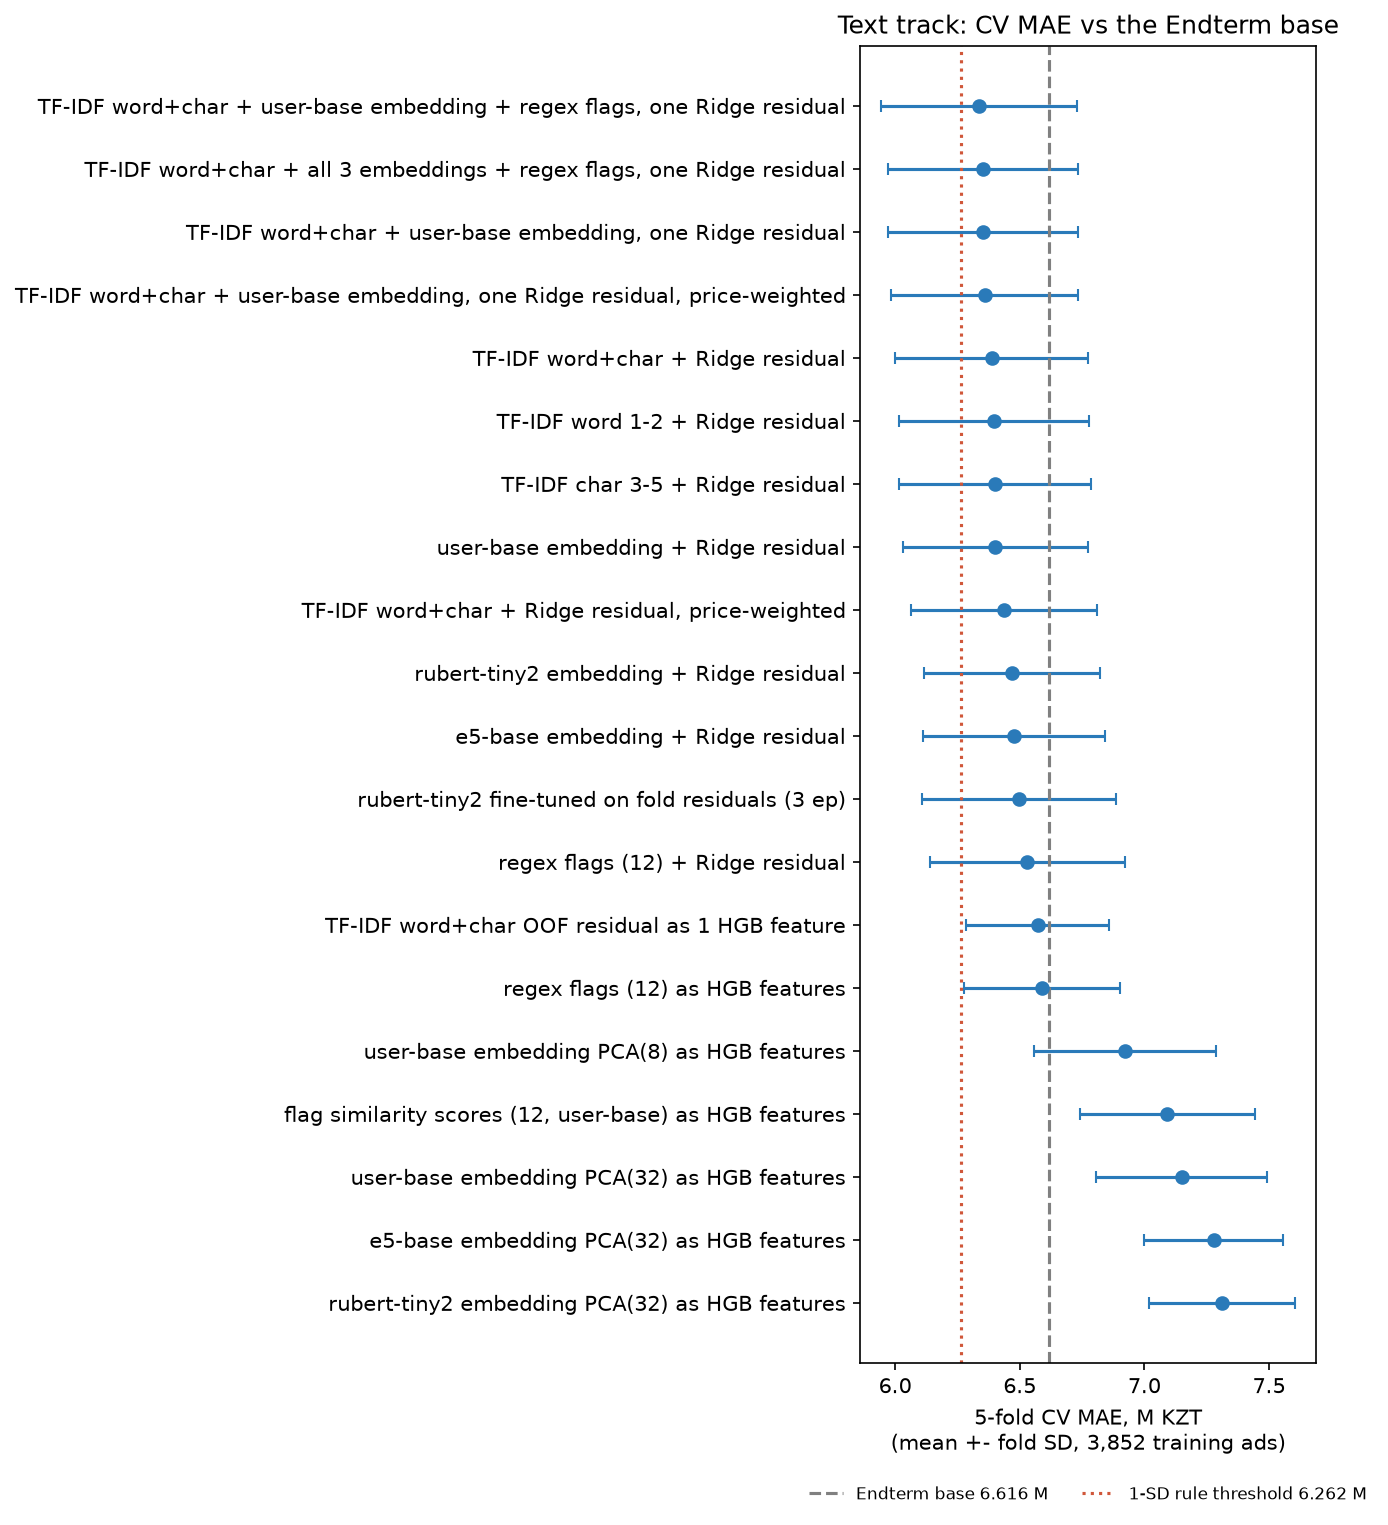

True

In [13]:
text_cv = show_cv("text/cv.csv")
show_figure("text/cv_text.png", width=820)

**Reading.** The best text variant, **TF-IDF word+char + user-base embedding + regex flags, one Ridge residual**, scores **6.336 ± 0.392 M**, -0.280 M against the base and better on **5 of 5 folds**; 0 of 20 text variants pass the 1-SD rule. TF-IDF word + character n-grams (6.388 M) and the frozen USER-base embedding (7.150 M) are equally good, and both beat feeding the embedding to the trees as 32 PCA features (7.313 M, worse than the base): a linear model on the residual uses all dimensions with a penalty, while the trees spend splits on noise. A gain on every fold is consistent, but its size stays below the rule's threshold of one fold SD (0.353 M), which is the honest summary of the text block: real, small, and below what five folds can certify. The transformer is not better than TF-IDF here because the descriptions are short, formulaic and in a mix of Russian and Kazakh, where the exact selling words ("designer renovation", "first line", "with furniture") matter more than paraphrase.

,term,coef,n_ads,direction,alpha
0,под,-0.091,862,down,4.642
1,документы,-0.090,947,down,4.642
2,возможность,-0.090,293,down,4.642
3,срочная,-0.085,68,down,4.642
4,срочная продажа,-0.084,64,down,4.642
5,студия,-0.081,606,down,4.642
6,школа,-0.080,988,down,4.642
7,ключи,-0.075,193,down,4.642
8,рядом школа,-0.073,165,down,4.642
9,реальным,-0.072,15,down,4.642


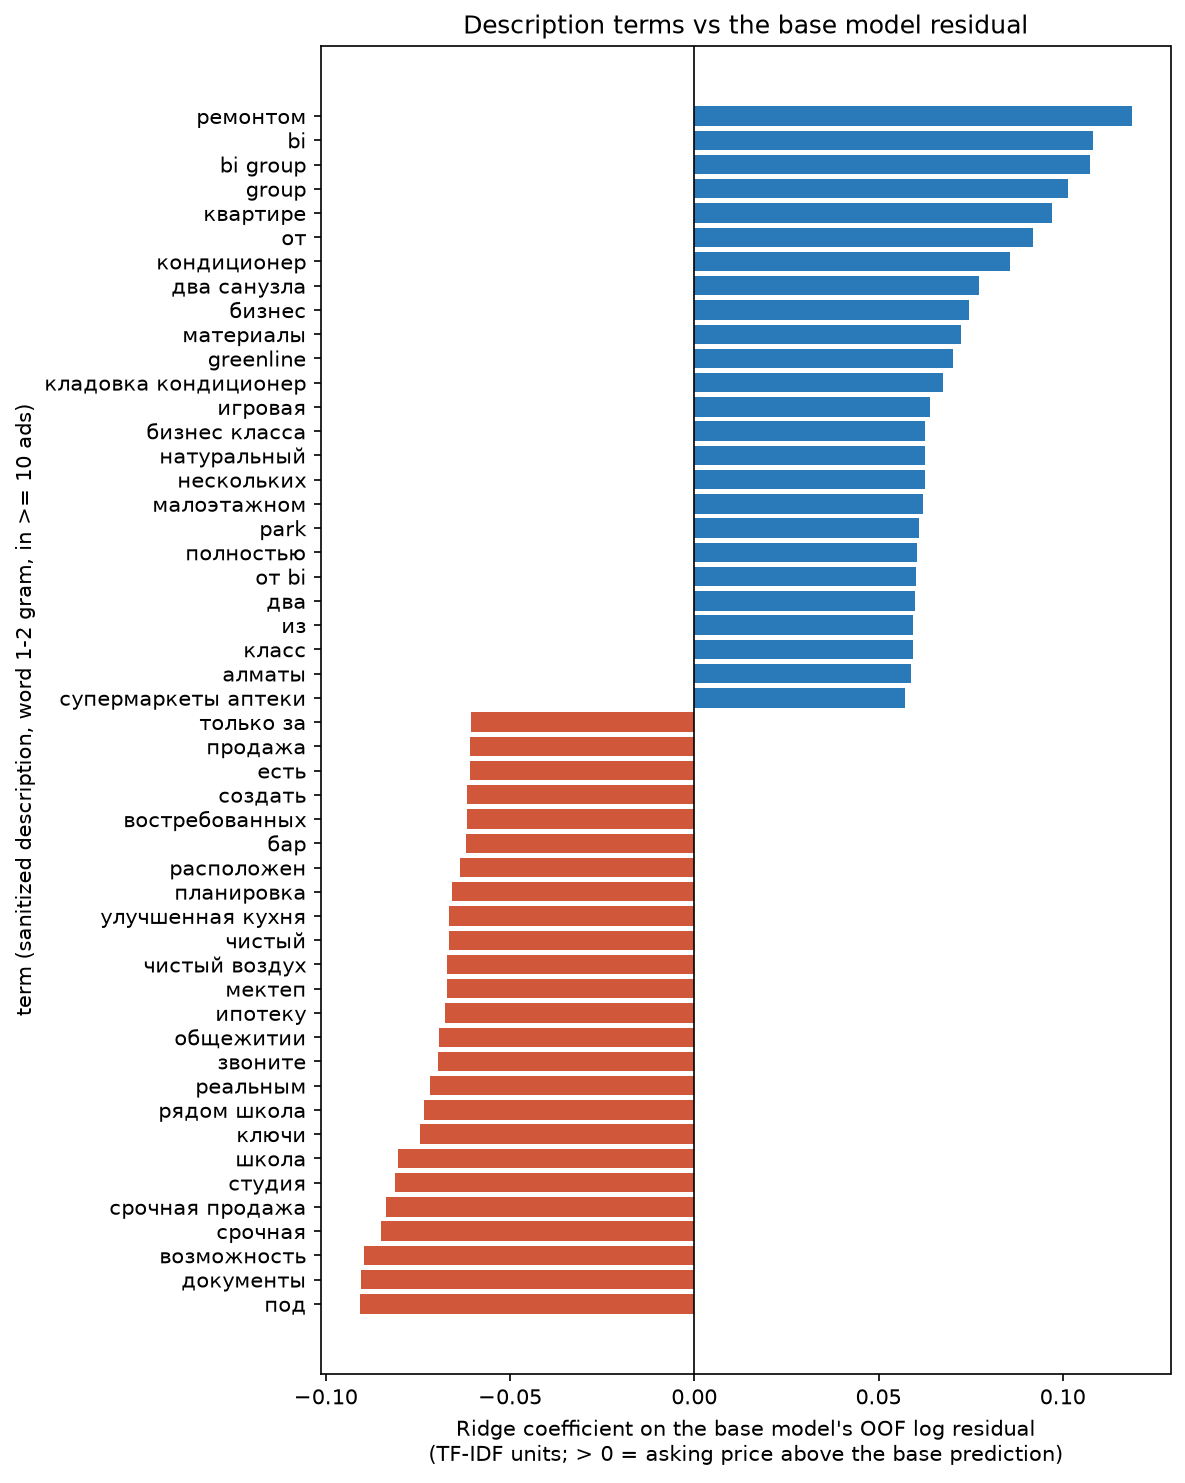

True

In [14]:
top = read_csv("text/top_terms.csv")
if top is not None:
    display(top.head(25))
show_figure("text/top_terms.png", width=820)

**Reading.** The n-grams that push the price *below* the base estimate are the words of a compromise or a hurry: «срочная продажа» (urgent sale), «документы» and «под» (as in «под ипотеку», documents and mortgage conditions), «студия», «ключи» (keys handed over: often a new, unfinished flat), «в общежитии» (in a dormitory), «звоните» (typical of agency templates). The ones that push it *up* name the building and the neighbourhood: «класс» (comfort/business class), «park» (complex names), «супермаркеты аптеки» (shops nearby), «полностью» (fully furnished / renovated). These are facts the 24 fields record coarsely or not at all, which is why a linear residual model on the text helps on every fold.

,share of training ads
flag_bargain,0.148
flag_rough_finish,0.100
flag_designer_renovation,0.098
flag_panoramic_view,0.080
flag_no_encumbrance,0.079
flag_urgent,0.076
flag_encumbrance,0.039
flag_cash_only,0.030
flag_assignment_of_rights,0.022
flag_needs_repair,0.012


,flag,n_train_ads,share_pct,median_resid_pct_flagged,ci95_lo_pct,ci95_hi_pct,median_resid_pct_rest,mean_abs_resid_pct_flagged,mannwhitney_p,n_all_clean_ads,sim_auc_vs_regex,sim_model
0,cash_only,114,2.96,-6.50,-9.05,-3.64,-0.33,14.27,1.320e-06,136,0.738,user-base
1,two_level,36,0.93,-6.17,-10.06,-1.76,-0.47,17.27,4.128e-02,44,0.772,user-base
2,assignment_of_rights,85,2.21,-5.41,-6.58,-2.39,-0.35,12.06,1.500e-04,122,0.867,user-base
3,former_dorm_text,32,0.83,-4.81,-9.91,-0.36,-0.49,13.25,4.655e-02,38,0.928,user-base
4,needs_repair,46,1.19,-3.66,-7.29,-0.73,-0.48,11.02,1.200e-01,60,0.755,user-base
5,rough_finish,387,10.05,-3.65,-5.92,-2.33,-0.15,12.96,7.719e-07,492,0.688,user-base
6,urgent,293,7.61,-2.82,-4.57,-1.47,-0.29,11.90,1.563e-05,358,0.738,user-base
7,panoramic_view,309,8.02,-1.99,-3.51,-0.53,-0.33,13.03,5.132e-01,387,0.692,user-base
8,encumbrance,149,3.87,-1.35,-3.28,0.46,-0.50,10.04,7.311e-01,184,0.680,user-base
9,bargain,571,14.82,-1.27,-1.99,-0.00,-0.35,12.38,4.920e-01,716,0.707,user-base


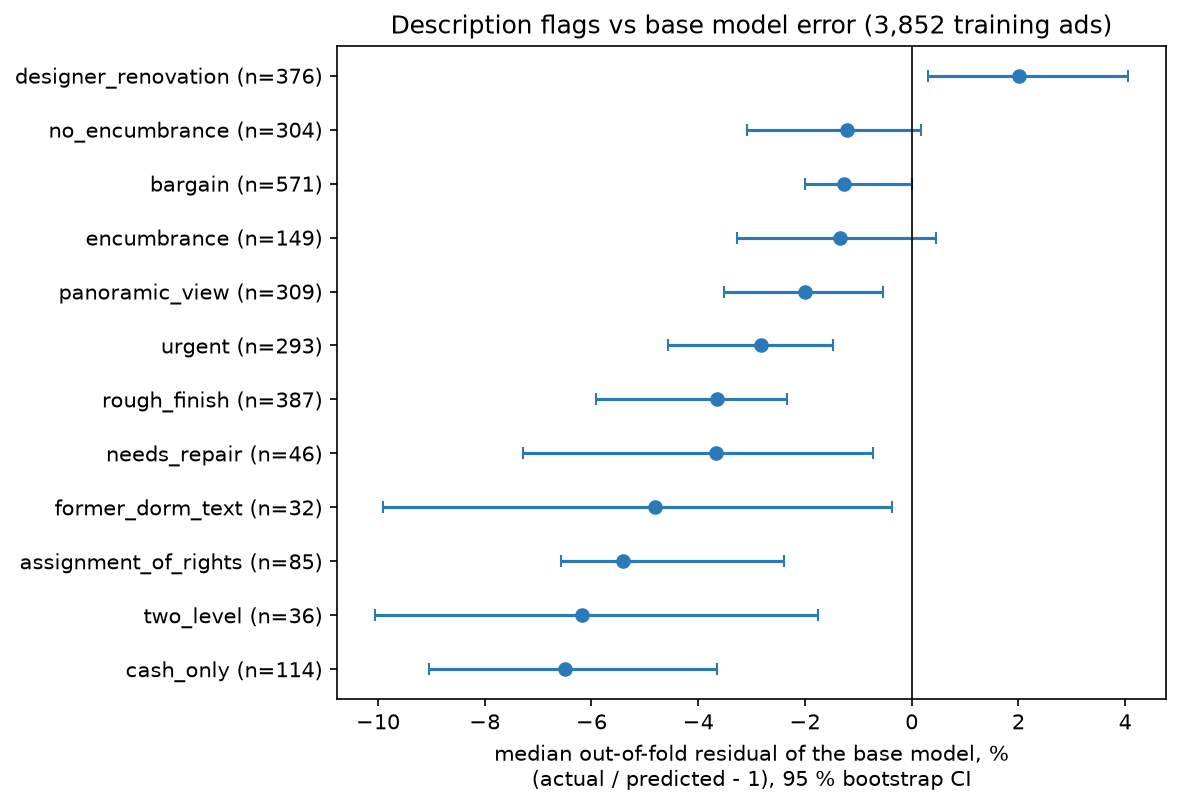

True

In [15]:
# Red flags: regex rules with negation handling (krisha_ml.text.extract_flags), checked against the base residuals
try:
    from krisha_ml import text as ktext
    flags = ktext.extract_flags(train.df)
    display(flags.drop(columns="id", errors="ignore").mean().sort_values(ascending=False).rename("share of training ads").to_frame().round(3))
except Exception as exc:   # the text module is optional for this cell
    print("flag extraction skipped:", exc)
stats = read_csv("text/flags_stats.csv")
if stats is not None:
    display(stats)
show_figure("text/flags_residuals.png", width=760)

**Reading.** Each flag is rare (1–15 % of the ads), and the table shows whether the base model already prices it (residual = log(asking / OOF estimate)): ads saying **cash only** are asked a median 6.5 % *below* the base estimate, **assignment of rights** (unfinished building) 5.4 % below, **former dormitory** 4.8 % below, **rough finish** 3.7 % and **urgent sale** 2.8 % below, all with 95 % intervals below zero; **designer renovation** is asked 2.0 % *above*. The market discounts legal and construction risk that the 24 fields do not record. Encumbrance, "price negotiable" and "no encumbrance" have intervals touching zero. Negation matters ("no encumbrance" is the opposite of "encumbrance"), which is why the rules handle it. The flags are shown to the user next to the estimate; as features of the HGB they add little (−0.05 M), because they are too rare to move a 5-fold MAE.

## 6. Fusion and model selection

**The rule.** A model is kept only if its 5-fold CV MAE is below the base by more than the fixed Endterm margin of 0.354 M, on the repaired (duplicate-aware) folds: below **6.370 M** (base 6.723 ± 0.264 M); the same candidate is reported on the random Endterm folds. The rule was fixed before the fused numbers were seen, and the test ads play no part. **Three fusion strategies** (`krisha_ml.fusion`, `scripts/run_final.py`): **A** residual stacking (the base HGB plus cross-fitted log-residual corrections, one per block: HGB for static blocks, Ridge for TF-IDF and embeddings, blended with non-negative weights learned on inner out-of-fold corrections); **B** the blocks as extra HGB columns (embeddings PCA-reduced inside the fold, text as an inner-OOF TF-IDF price prior); **C** a small PyTorch network (tabular branch + text-embedding branch + photo-embedding branch, L1 loss on the standardised log price, early stopping, 2 seeds), alone and **50/50 log-blended with the base** (weight fixed in advance, not tuned).

**Two readings of the rule.** (1) *Strict per-step forward selection* for A and B: blocks are added greedily, and each step must lower the CV MAE by more than max(fold SD of the current set, 0.354 M). (2) *Whole-model comparison*: a complete fused model (all blocks, one strategy) is compared with the base by the same rule. Reading (1) asks "is every single block certified?", reading (2) "is the whole model certified?". We report both and choose by (2), with one safeguard taken from (1): the gain of the network blend must come from the blocks, not from blending alone, so the blend of the base with a *tabular-only* network is the control.

folds,CV MAE repaired folds,CV MAE random folds,SD (repaired),Δ vs base (repaired),passes rule (repaired),passes rule (random)
variant,,,,,,
Endterm base,6.723,6.616,0.264,0.000,False,False
A: geo+rawfields+photo+text_flags+text+text_emb+photo_emb,6.253,6.170,0.372,-0.470,True,True
B: geo+rawfields+photo+text_flags+text+text_emb+photo_emb,6.365,6.445,0.397,-0.358,True,False
"C: network, tabular only",8.596,8.598,0.316,1.872,False,False
"C: network, all blocks",7.293,7.258,0.346,0.570,False,False
"C: network, all blocks, 50/50 log-blend with base",6.100,6.092,0.388,-0.623,True,True


strategy        A             B       
folds       group random  group random
blocks                                
geo         6.572  6.489  6.510  6.531
photo       6.482  6.352  6.816  6.776
photo_emb   6.548  6.435  6.810  6.712
rawfields   6.700  6.570  6.753  6.766
text        6.513  6.402  6.691  6.849
text_emb    6.519  6.402  7.016  7.052
text_flags  6.678  6.559  6.586  6.588

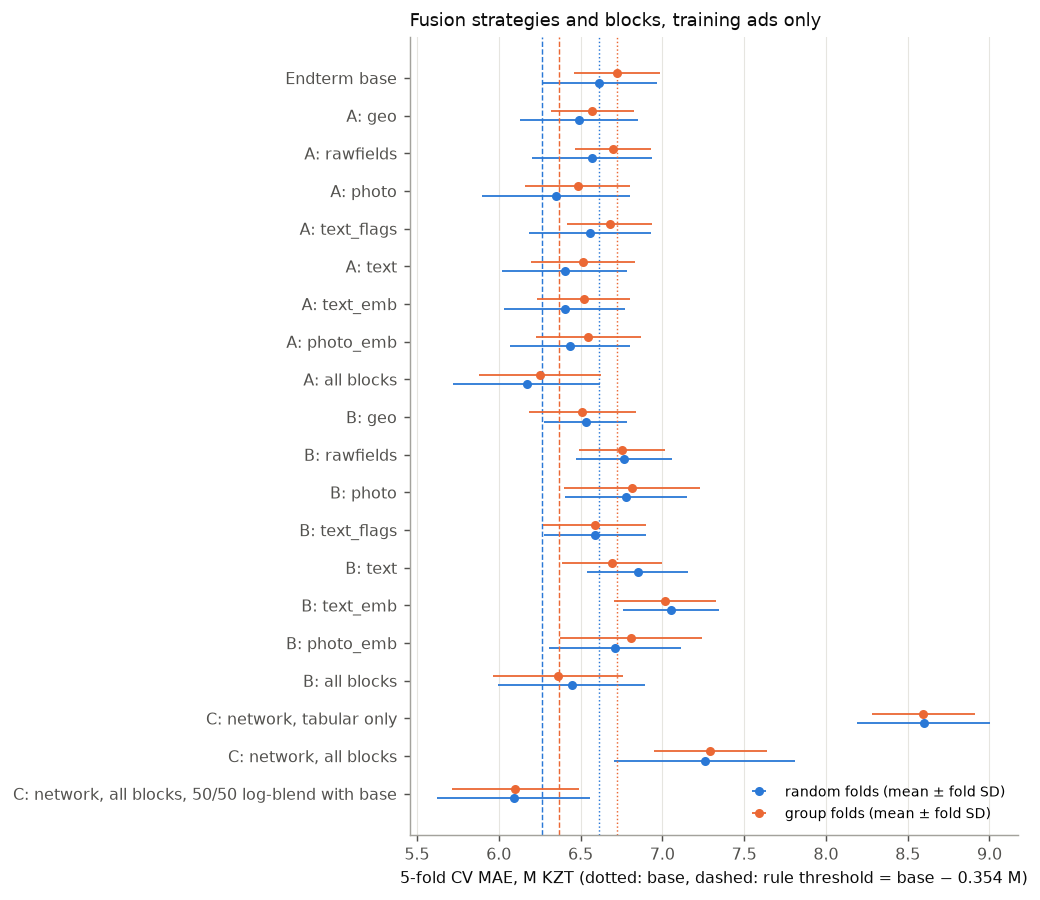

True

In [16]:
cmp = read_csv("final/cv_comparison.csv")
if cmp is not None:
    keep = cmp[(cmp["kind"] != "single")]
    v = keep.pivot_table(index="variant", columns="folds", values="cv_mae_M", sort=False)
    v["SD (repaired)"] = keep[keep.folds == "group"].set_index("variant")["cv_mae_sd_M"]
    v["Δ vs base (repaired)"] = keep[keep.folds == "group"].set_index("variant")["delta_vs_base_M"]
    v["passes rule (repaired)"] = keep[keep.folds == "group"].set_index("variant")["passes_1sd_rule"]
    v["passes rule (random)"] = keep[keep.folds == "random"].set_index("variant")["passes_1sd_rule"]
    display(v.rename(columns={"group": "CV MAE repaired folds", "random": "CV MAE random folds"}).round(3))
    singles = cmp[cmp["kind"] == "single"].pivot_table(index="blocks", columns=["strategy", "folds"], values="cv_mae_M")
    display(singles.round(3))
show_figure("final/fig_model_comparison.png", width=820)

**Reading.** On the repaired folds no single block passes the rule in any strategy: the best single blocks lower the CV MAE by 0.15–0.24 M (residual stacking A: photo features 6.482 M, text TF-IDF 6.513 M), against a margin of 0.354 M. Together they do more: strategy A with all seven blocks reaches 6.253 M, the HGB with all blocks as features (B) 6.365 M (just above the threshold). The network alone is clearly worse than the base (7.293 M; tabular only 8.595 M: 3,852 rows are few for a network), but its errors are different from the trees', so the **50/50 log-blend with the base** gives the lowest CV MAE of all: **6.100 ± 0.388 M**, 0.623 M below the base (more than the 0.354 M margin), better on all five folds, and the same on the random folds (6.092 M against 6.616). The gain is about the same on both fold schemes, so it does not come from duplicate ads.

**Strict per-step forward selection and the ablation of the blend** (repaired folds, final blocks, step margin = max(fold SD of the current set, 0.354 M)).

added  cv_mae_M     gain_M  step_sd_M  folds_better_than_prev  passes_step_rule  set_passes_vs_base
strategy step                                                                                                          
A        1          photo     6.482  2.406e-01      0.264                       5             False               False
         2       text_emb     6.350  1.325e-01      0.321                       5             False                True
         3            geo     6.258  9.210e-02      0.348                       5             False                True
         4           text     6.248  9.600e-03      0.346                       2             False                True
         5     text_flags     6.247  1.800e-03      0.368                       3             False                True
         6      rawfields     6.246  6.000e-04      0.372                       1             False                True
B        1            geo     6.510  2.133e-01      0.264                       4             False               False
         2     text_flags     6.408  1.015e-01      0.327                       4             False               False
         3      rawfields     6.398  1.050e-02      0.274                       2             False               False

,cv_mae_M,cv_mae_sd_M,delta_vs_base_M,folds_better
variant,,,,
Cb: tabular only (ensembling control),7.134,0.229,0.411,0
Cb: embeddings only: text_emb+photo_emb,6.293,0.346,-0.430,5
Cb: all minus geo,6.391,0.462,-0.332,4
Cb: all minus rawfields,6.076,0.466,-0.647,5
Cb: all minus photo,6.033,0.366,-0.690,5
Cb: all minus text_flags,6.104,0.389,-0.620,5
Cb: all minus text_emb,6.191,0.337,-0.532,5
Cb: all minus photo_emb,6.161,0.381,-0.562,5
Cb: all blocks,6.100,0.388,-0.623,5


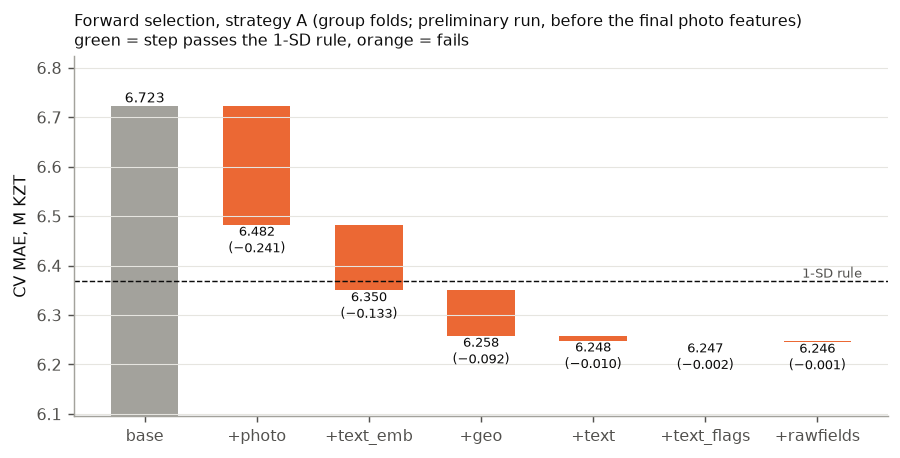

True

In [17]:
fs = read_csv("final/forward_selection.csv")
if fs is not None:
    display(fs[["strategy", "step", "added", "cv_mae_M", "gain_M", "step_sd_M", "folds_better_than_prev", "passes_step_rule", "set_passes_vs_base"]].set_index(["strategy", "step"]))
abl = read_csv("final/cv_network_ablation.csv")
if abl is not None:
    display(abl[abl.variant_kind == "blend"][["variant", "cv_mae_M", "cv_mae_sd_M", "delta_vs_base_M", "folds_better"]].set_index("variant").round(3))
show_figure("final/fig_ablation_waterfall.png", width=760)

**Reading.** Read strictly step by step, **no block is ever certified**: the first and largest step (photo features in A, −0.24 M; location in B, −0.21 M) is already below the 0.354 M margin, and every later step adds less (A: text embedding 0.13, location 0.09, then ≤ 0.01 M; B: text flags 0.10, then 0.01 M). So the strict per-step reading keeps the Endterm base. The ablation answers why the blend still wins: blending the base with a network that sees only the 24 tabular fields gives 7.134 M, *worse* than the base, so the gain is not plain ensembling; it comes from the blocks, and from several of them at once: location matters most (without it the blend gets 6.391 M, +0.29 M, and no longer passes), the text and photo embeddings add 0.09 and 0.06 M, the embeddings alone already give most of the gain (6.293 M), and dropping the photo-track tabular features or the raw fields would even lower the CV slightly (6.033 and 6.076 M, within fold noise). We keep the block set fixed before the ablation rather than re-pick it from these numbers.

**The decision.** The final model is the **network + Endterm base 50/50 log-blend** with the blocks geo, raw fields, photo features, text flags, text embedding and photo embedding. It wins the whole-model comparison by 0.623 M > 0.354 M on the primary folds, its blocks beat the tabular-only control, and it is the lowest CV of every candidate on both fold schemes. We do not claim that any *single* block is certified: the per-step reading keeps none, and we say so. The choice used only training-ad CV; the test ads were scored once, afterwards (Section 8).

## 7. The trust layer: intervals, explanations, comparables and the over-pricing flag

A point estimate with an MAE of 6 M KZT cannot tell a buyer whether *this* ad is over-priced: the error is 2 M for a small flat and 30 M for a penthouse. We add four things (script `run_trust.py`, module `krisha_ml.trust`).

**Conformal prediction.** Split/cross conformal prediction turns any model into intervals with a guaranteed coverage: compute a non-conformity score on calibration ads that the model did not see (here, out-of-fold), take its (1 − α) quantile with the finite-sample correction ⌈(n+1)(1−α)⌉/n, and widen every prediction by it. The guarantee is marginal (on average over ads), so we check coverage per city and per price band. We compare (a) intervals of constant width on the log-residual of the base model and (b) **conformalized quantile regression (CQR)**: two boosting models predict the 5 % and 95 % (10 %, 90 %) quantiles, and conformal calibration corrects their coverage, giving intervals that are wide where the market is uncertain and narrow where it is not; calibration can be per city (Mondrian).

coverage  coverage_fold_sd  coverage_Almaty  coverage_Astana  min_band_coverage  min_estimate_band_coverage  mean_width_M  median_width_M  \
level variant                                                                                                                                                                                       
0.8   abs-residual (base HGB) | Mondrian city              0.815             0.013            0.820            0.809              0.585                       0.608        18.826          15.511   
      abs-residual (base HGB) | global                     0.815             0.014            0.816            0.815              0.585                       0.608        18.835          15.543   
      abs-residual (base HGB) | Mondrian estimate band     0.818             0.018            0.822            0.814              0.740                       0.802        21.252          15.007   
      CQR endterm crossfit | Mondrian city                 0.810             0.010            0.808            0.811              0.713                       0.792        24.244          16.229   
      CQR smooth crossfit | global                         0.811             0.018            0.797            0.824              0.679                       0.791        24.246          16.244   
      CQR endterm crossfit | global                        0.810             0.012            0.799            0.819              0.713                       0.788        24.253          16.212   
      CQR smooth crossfit | Mondrian city                  0.810             0.016            0.803            0.816              0.672                       0.787        24.262          16.272   
      CQR endterm split | global                           0.801             0.014            0.793            0.808              0.672                       0.767        24.425          16.556   
      CQR endterm split | Mondrian city                    0.804             0.015            0.802            0.806              0.668                       0.764        24.514          16.725   
      CQR smooth split | global                            0.808             0.025            0.799            0.816              0.657                       0.775        24.740          16.520   
      CQR smooth split | Mondrian city                     0.810             0.023            0.804            0.815              0.649                       0.767        24.810          16.625   
0.9   abs-residual (base HGB) | global                     0.911             0.007            0.914            0.908              0.713                       0.744        25.633          21.166   
      abs-residual (base HGB) | Mondrian city              0.910             0.006            0.914            0.906              0.713                       0.740        25.633          21.209   
      abs-residual (base HGB) | Mondrian estimate band     0.907             0.003            0.912            0.903              0.845                       0.903        29.073          19.976   
      CQR endterm crossfit | global                        0.912             0.009            0.910            0.914              0.789                       0.876        33.314          23.158   
      CQR endterm crossfit | Mondrian city                 0.912             0.010            0.912            0.912              0.789                       0.876        33.356          23.181   
      CQR smooth crossfit | global                         0.906             0.010            0.903            0.909              0.736                       0.857        33.476          23.150   
      CQR smooth crossfit | Mondrian city                  0.908             0.008            0.906            0.910              0.732                       0.853        33.524          23.205   
      CQR endterm split | Mondrian city                    0.906             0.014            0.912            0.900

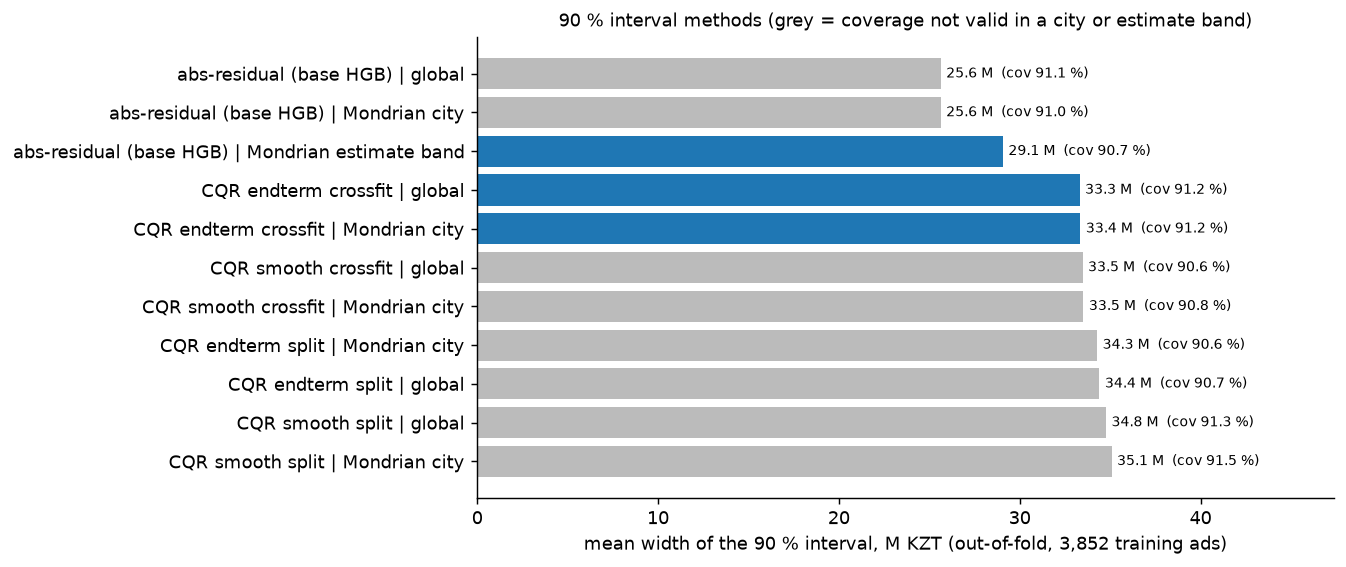

True

In [18]:
im = read_csv("trust/interval_methods.csv")
if im is not None:
    display(im.set_index(["level", "variant"]).round(3))
show_figure("trust/interval_methods_width.png", width=760)

**Reading.** All methods reach their nominal coverage on average (90.6–91.5 % at the 90 % level), as conformal theory promises; they differ in *where* they are wide. The chosen method, **abs-residual (base HGB) | Mondrian estimate band**, covers 90.7% of the training ads out of fold at the 90 % level (80 % level: 81.8%) with a mean width of 29.1 M KZT and a median relative width of 48 %. It was chosen by a fixed rule: valid coverage in both cities at both levels, then the narrowest mean 90 % width.

level     n  coverage  share_above  share_below  mean_width_M  median_width_M  median_rel_width_pct
group_type    group                                                                                                        
overall       all         0.9  3852     0.907        0.049        0.044        29.073          19.976                48.137
city          Almaty      0.9  1849     0.912        0.049        0.039        32.308          21.234                48.535
              Astana      0.9  2003     0.903        0.049        0.048        26.087          16.316                47.877
price band    25-40 M     0.9  1381     0.919        0.028        0.053        14.576          13.822                43.658
              40-60 M     0.9  1097     0.922        0.052        0.026        24.309          23.164                48.472
              60-100 M    0.9   629     0.903        0.075        0.022        47.526          45.289                61.864
              <25 M       0.9   480     0.881        0.010        0.108        10.436          10.707                50.115
              >=100 M     0.9   265     0.845        0.151        0.004       114.305         108.080                79.416
estimate band 25-40 M     0.9  1374     0.906        0.050        0.044        13.710          13.679                42.429
              40-60 M     0.9  1149     0.910        0.046        0.044        23.605          23.306                49.240
              60-100 M    0.9   607     0.903        0.054        0.043        47.831          46.251                64.595
              <25 M       0.9   464     0.905        0.045        0.050        10.354          10.572                48.852
              >=100 M     0.9   258     0.919        0.050        0.031       124.779         110.902                89.825
fold          1           0.9   771     0.905        0.053        0.042        26.580          20.022                46.560
              2           0.9   771     0.903        0.053        0.044        28.401          19.209                46.275
              3           0.9   770     0.908        0.048        0.044        28.900          20.852                49.546
              4           0.9   770     0.910        0.040        0.049        29.620          19.682                49.398
              5           0.9   770     0.910        0.049        0.040        31.870          20.465                48.797

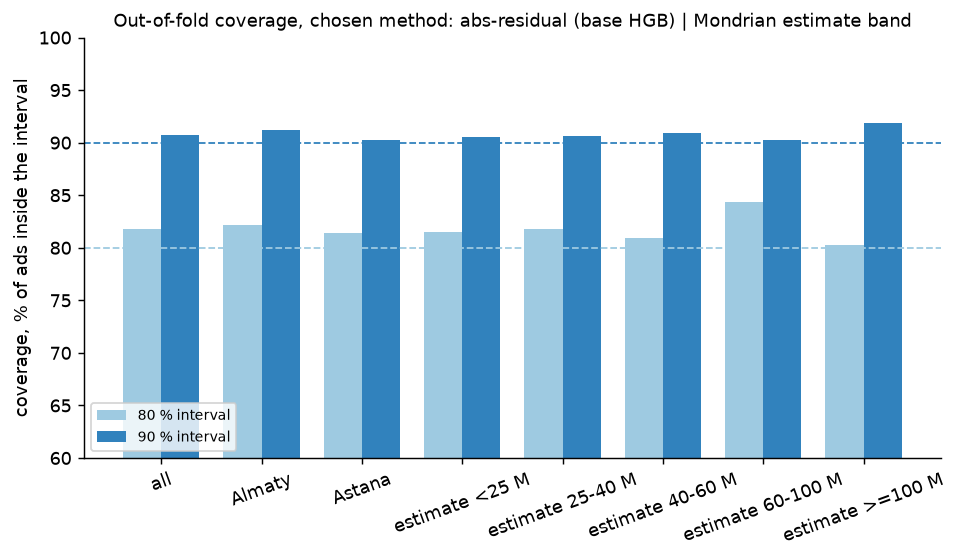

True

In [19]:
cov = read_csv("trust/coverage_table.csv")
if cov is not None and im is not None:
    chosen = im.loc[im["chosen"].astype(str).str.lower() == "true", "variant"].iloc[0] if "chosen" in im else cov["variant"].iloc[0]
    display(cov[(cov["variant"] == chosen) & (cov["level"] == 0.9)].drop(columns=["variant"]).set_index(["group_type", "group"]).round(3))
show_figure("trust/coverage_chosen.png", width=760)

**Reading.** Coverage per city and per band is the real test of an interval: a method can reach 90 % overall by over-covering standard flats and under-covering expensive ones. With one global width the 90 % interval covers only 74 % of the ads whose *estimate* is above 100 M; calibrating separately per band of the estimate (known at prediction time) fixes this: every estimate band is covered 90.3–91.9 %, both cities 90.3–91.2 %, every fold 90.3–91.0 %, at the price of a wider interval for expensive flats (upper bound +23 % over the estimate for 25–40 M, +54 % above 100 M). By band of the *true* price, coverage is still lower at the extremes (84.5 % above 100 M, 88.1 % below 25 M): the ads that turn out most expensive are exactly those the model under-predicts, a regression-to-the-mean effect that no calibration on the estimate can remove.

n  over_interval90  under_interval90  over_endterm20  under_endterm20  over_both
group_type    group                                                                                        
overall       all       3852            0.049             0.044           0.099            0.060      0.049
city          Almaty    1849            0.049             0.039           0.101            0.055      0.049
              Astana    2003            0.049             0.048           0.097            0.065      0.049
price band    <25 M      480            0.010             0.108           0.025            0.112      0.010
              25-40 M   1381            0.028             0.053           0.046            0.051      0.028
              40-60 M   1097            0.052             0.026           0.096            0.049      0.052
              60-100 M   629            0.075             0.022           0.172            0.060      0.075
              >=100 M    265            0.151             0.004           0.347            0.057      0.151
estimate band <25 M      464            0.045             0.050           0.084            0.062      0.045
              25-40 M   1374            0.050             0.044           0.074            0.036      0.050
              40-60 M   1149            0.046             0.044           0.097            0.053      0.046
              60-100 M   607            0.054             0.043           0.128            0.087      0.054
              >=100 M    258            0.050             0.031           0.198            0.155      0.050

,in range,over,under,All
flag_endterm20,,,,
in range,3227,0,12,3239
over,193,188,0,381
under,75,0,157,232
All,3495,188,169,3852


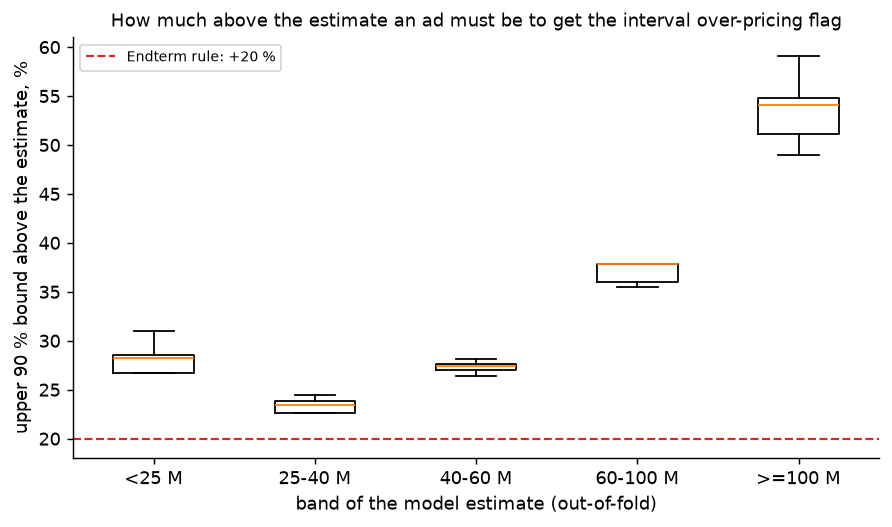

True

In [20]:
ov = read_csv("trust/overpricing_shares.csv")
if ov is not None:
    display(ov.set_index(["group_type", "group"]).round(3))
xt = read_csv("trust/overpricing_crosstab.csv", index_col=0)
if xt is not None:
    display(xt)
show_figure("trust/flag_threshold_by_band.png", width=760)

**Reading.** The new flag says "over-priced" only when the asking price is above the upper end of the 90 % interval. Out of fold it flags 4.9% of the training ads, against 9.9% for the Endterm's "> 20 % above the estimate" rule; every ad the interval flags is also flagged by the 20 % rule (Jaccard 0.49), so the new flag is the stricter half. The difference grows with the price: the 20 % rule flags 8 % of the ads estimated below 25 M but 20 % of those above 100 M, the interval rule 4.5–5.4 % in every band, because its threshold adapts to how well the model knows each kind of flat (+23–28 % for standard flats, +54 % above 100 M).

**SHAP.** Shapley values split one prediction into additive contributions of the features, so that base value + contributions = the predicted log price; for trees they are computed exactly (TreeSHAP). We sum the contributions of one-hot columns back to their source feature.

,mean_abs_shap_log,mean_abs_shap_log_ordinal_twin,rank,rank_ordinal_twin
feature,,,,
area,0.287,0.283,1,1
location,0.157,0.157,2,2
ceiling_height,0.053,0.055,3,3
year_built,0.052,0.050,4,4
rooms,0.027,0.026,5,5
condition,0.026,0.026,6,6
furnished,0.024,0.025,7,7
n_photos,0.020,0.020,8,8
floor,0.013,0.014,9,9


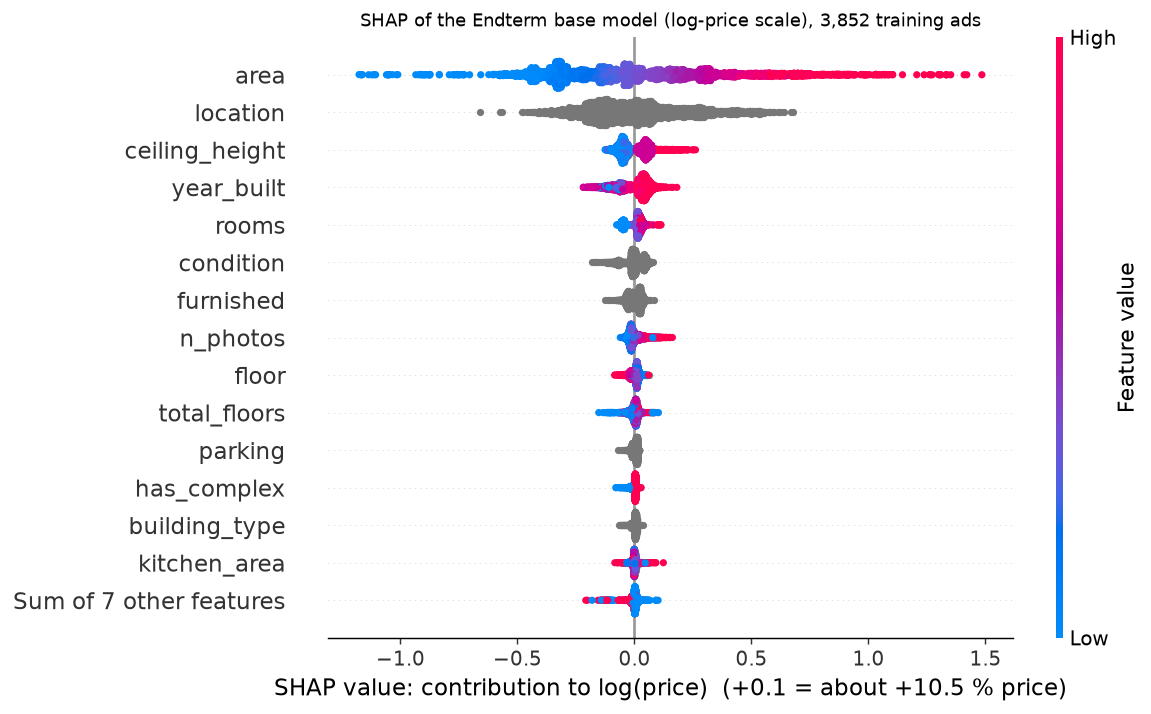

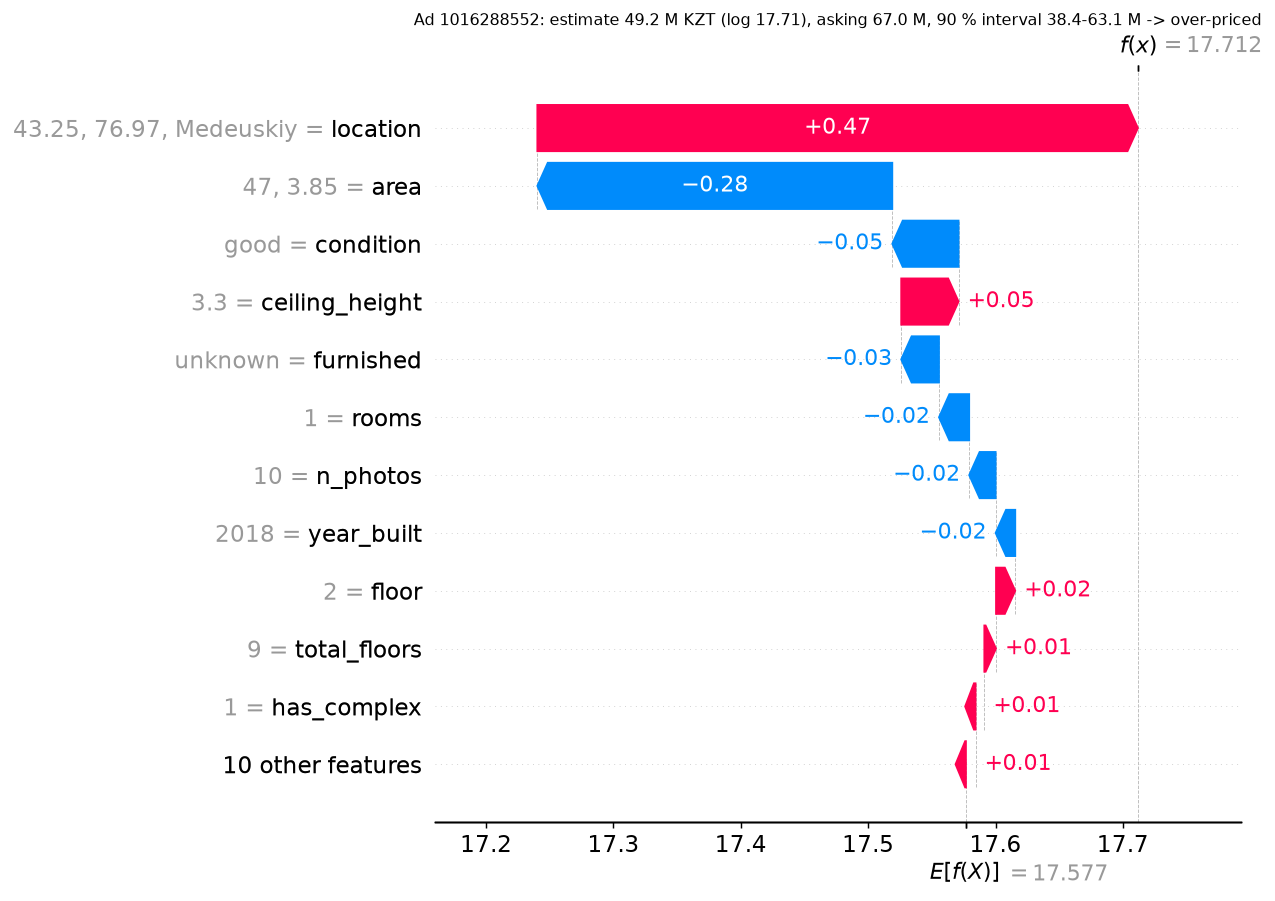

True

In [21]:
shap_imp = read_csv("trust/shap_global_importance.csv", index_col=0)
if shap_imp is not None:
    display(shap_imp.head(12).round(4))
show_figure("trust/shap_beeswarm.png", width=760)
show_figure("trust/shap_waterfall_example.png", width=760)

**Reading.** SHAP confirms the Endterm's permutation importance: **area** has the largest mean absolute contribution to the log price (0.29), followed by location (0.16) and ceiling_height (0.05). The ranking is stable when the one-hot model is replaced by an ordinal twin (Spearman 1.00), so it does not depend on how the categories were encoded. The waterfall shows the reasons for one ad as percentages of the estimate. SHAP explains the *model*, not the market: a feature correlated with a missing one (ceiling height with building class) takes its credit. In the app, SHAP explains the HGB half of the final blend (the network has no exact TreeSHAP), and the app says so.

**Comparable ads.** For every ad we show the 5 most similar training ads in the same city (log area, rooms, year, floor, position in km), with their prices per m², and warn when even the 5th neighbour is far, i.e. when the estimate rests on few comparables (the DBSCAN "noise" idea of the Endterm made quantitative).

,n,share,base_mae_M,base_mdape_pct,median_rel_width90_pct,over_or_under_flag_share
few comparables,198.0,0.051,12.614,11.345,50.778,0.187
enough comparables,3654.0,0.949,6.291,8.766,48.314,0.088


,query_id,rank,comp_id,comp_price,area,rooms,year_built,floor,district,lat,lon,distance,dist_k,few_comparables,comp_price_m2
0,1016288552,1,1013028320,9.500e+07,45.0,1.0,2025.0,2.0,Medeuskiy,43.242,76.962,0.396,1.04,False,2.111e+06
1,1016288552,2,1013944438,6.489e+07,48.0,1.0,2025.0,2.0,Bostandykskiy,43.225,76.929,0.854,1.04,False,1.352e+06
2,1016288552,3,1010386475,4.100e+07,36.0,1.0,2024.0,3.0,Almalinskiy,43.264,76.934,1.010,1.04,False,1.139e+06
3,1016288552,4,1002157386,6.490e+07,35.0,1.0,2024.0,4.0,Medeuskiy,43.261,76.982,1.019,1.04,False,1.854e+06
4,1016288552,5,1014441289,4.400e+07,47.0,1.0,2022.0,5.0,Zhetysuskiy,43.272,76.947,1.040,1.04,False,9.362e+05


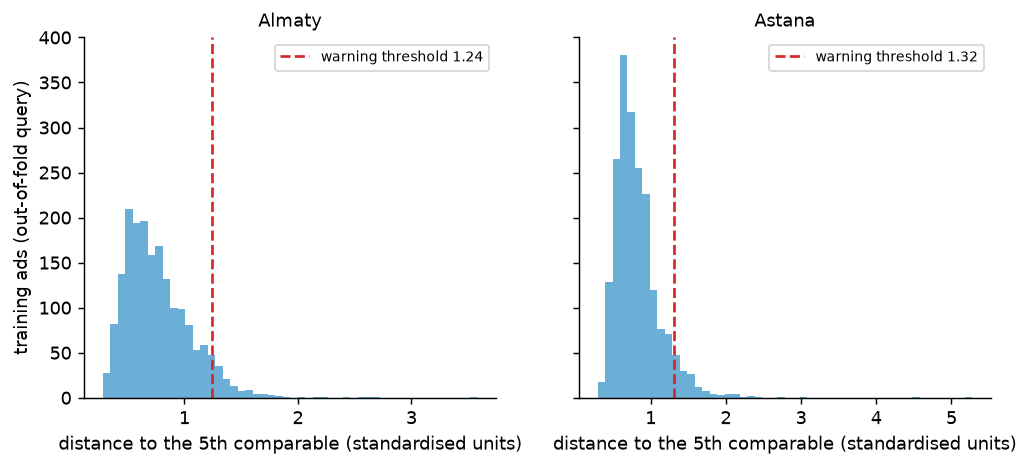

True

In [22]:
cw = read_csv("trust/comparables_warning_check.csv", index_col=0)
if cw is not None:
    display(cw.round(3))
ce = read_csv("trust/comparables_example.csv")
if ce is not None:
    display(ce)
show_figure("trust/comparables_distance.png", width=760)

**Reading.** The warning fires for 5.1% of the training ads, and on those ads the base model's error is twice as large as on the rest (MAE 12.6 against 6.3 M, MdAPE 11.3 against 8.8 %): the warning is informative, it marks exactly the ads where the estimate should be trusted less. The comparables themselves are the most convincing output for a non-technical user, because they are real ads that can be opened and checked.

## 8. The single test evaluation and the November temporal hold-out

The 963 test ads, saved at the Midterm, are scored **once**, by the model chosen in Section 6, after every choice was fixed; the Endterm base is scored on the same ads for comparison. Confidence intervals are 95 % bootstrap intervals over the test ads. The November hold-out is a different kind of test: **1,507 ads scraped on 8 November 2026**, a month after the training data, from the search pages only (the ad pages were blocked by the site's bot protection that day), so they have no coordinates, no full description and no photos, and kitchen area, balcony and parking are missing. It answers a question the random split cannot: does the model still work a month later, on ads it could not have seen, with the inputs it would have in a quick check from a search page?

In [23]:
tm = read_json("final_eval/test_metrics.json")
if tm:
    display(pd.DataFrame({k: v for k, v in tm.items() if isinstance(v, dict)}).T.round(3))
res = read_csv("final_eval/results_table.csv", index_col=0)
if res is not None:
    display(res)

,mae_M,rmse_M,mdape,r2,within10,within20,bootstrap95_mae,bootstrap95_mdape
chosen,5.801,14.003,7.824,0.853,0.599,0.884,"[5.092273859305514, 6.674253279789067]","[7.444230336067818, 8.530424759626285]"
base,6.291,13.895,9.129,0.855,0.537,0.843,"[5.558868059666891, 7.143959118905817]","[8.305910924684635, 9.882162636618629]"


,cv_mae_M,cv_mdape,test_mae_M,test_rmse_M,test_mdape,test_r2,test_within10,test_within20
model,,,,,,,,
Endterm base,6.616,8.934,6.291,13.895,9.129,0.855,0.537,0.843
"C network + base, 50/50 log-blend (geo+rawfields+photo+text_flags+text_emb+photo_emb)",6.092,NaN,5.801,14.003,7.824,0.853,0.599,0.884


**Reading.** On the 963 test ads the chosen model reaches **MAE 5.80 M KZT** (95 % bootstrap 5.09–6.67), **MdAPE 7.82 %**, R² 0.853, 88% of ads within ±20 %, against MAE 6.29 M and MdAPE 9.13 % for the Endterm model on the same ads. The paired bootstrap of the difference (same resampled ads for both models) gives **-0.80 to -0.16 M**: the improvement of the CV (−0.62 M on the repaired folds) is confirmed on unseen ads, about −0.49 M. It is an improvement of the typical ad, not of the extremes: RMSE (14.00 against 13.89 M) and R² (0.853 against 0.855) are unchanged, because the largest errors (flats above 100 M) are not smaller. Two caveats: this is the **second** use of the 963 test ads (the Endterm scored them once), so they are no longer a perfectly fresh sample, although no Final choice looked at them; and 13 test ads (1.35 %) have a duplicate in the training ads, too few to move the MAE.

November ads: 1,507 {'Almaty': 754, 'Astana': 753}, scraped 2026-11-08; missing vs October: lat, lon, street, house_num, kitchen_area, n_photos, balcony, parking, former_dorm, exchange, full description, photos


,n,mae_M,mae_ci_low,mae_ci_high,mdape,mdape_ci_low,mdape_ci_high,r2,within10,median_log_error
chosen,1507.0,7.719,7.047,8.461,10.507,9.754,11.264,0.780,0.486,0.007
base,1507.0,12.161,11.374,13.110,18.672,17.735,19.784,0.639,0.293,-0.019
chosen_on_oct_test,963.0,7.596,6.749,8.608,10.157,9.304,10.899,0.789,0.497,-0.002


,n,mae_M,mae_ci_low,mae_ci_high,mdape,mdape_ci_low,mdape_ci_high,r2,within10,median_log_error
Almaty,754.0,8.336,7.267,9.565,9.858,8.954,11.015,0.782,0.505,0.002
Astana,753.0,7.103,6.361,7.920,10.956,9.959,11.899,0.759,0.467,0.010


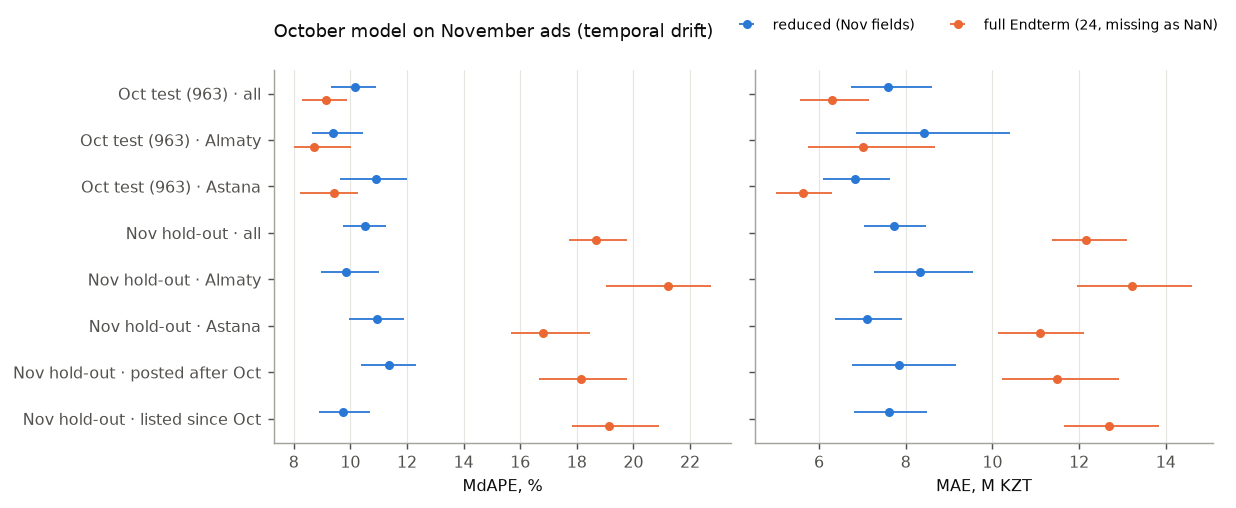

True

In [24]:
nov_meta = read_json("nov_holdout/build_meta.json")
if nov_meta:
    print(f"November ads: {nov_meta['rows_out']:,} {nov_meta['by_city']}, scraped {nov_meta['scraped_at_range'][0][:10]}; "
          f"missing vs October: {', '.join(nov_meta['fields_missing_vs_october'])}")
nov = read_json("final_eval/nov_holdout.json")
if nov:
    display(pd.DataFrame({k: v for k, v in nov.items() if isinstance(v, dict) and k != "by_city"}).T.round(3))
    if "by_city" in nov:
        display(pd.DataFrame(nov["by_city"]).T.round(3))
show_figure("final_eval/nov_holdout.png", width=760)

**Reading.** The November cards carry 17 of the 24 fields and none of the Final blocks, so the fused model cannot be applied to them. To measure *time* separately from *missing inputs*, we retrained the Endterm HGB on the October training ads with only the fields the cards carry, and scored it on the October test ads and on the November ads: MdAPE **10.16 % → 10.51 %**, MAE 7.60 → 7.72 M, median log error +0.007 (the October model is not biased a month later; median price per m² rose 1.8 % in Almaty and 1.0 % in Astana). A month of drift costs about 0.35 percentage points of MdAPE, within the bootstrap intervals; the missing inputs cost much more (the full model with the missing fields left empty: MdAPE 18.67 %, so a model must be trained for the inputs it will see). Limits: the hold-out is at listing level only (the ad pages were blocked by the site's bot protection on 8 November), and the intervals were not re-checked on it.

## 9. Error analysis

,value,n,mae_M,mae_ci_low,mae_ci_high,mdape,median_log_error,within10,base_mae_M,base_mdape,diff_mae_M,diff_ci_low,diff_ci_high
segment,,,,,,,,,,,,,
city,Almaty,463,6.647,5.344,8.403,7.569,0.003,0.611,7.014,8.702,-0.366,-0.902,0.222
city,Astana,500,5.018,4.454,5.623,8.303,0.012,0.588,5.622,9.425,-0.604,-0.977,-0.259
price_band,25-40M,338,2.790,2.517,3.063,6.666,0.026,0.666,3.210,7.920,-0.420,-0.624,-0.230
price_band,40-60M,271,4.675,4.249,5.117,7.824,-0.002,0.616,5.008,8.565,-0.332,-0.711,0.014
price_band,60-100M,178,8.627,7.718,9.605,9.904,-0.042,0.517,9.788,11.551,-1.160,-2.050,-0.300
price_band,<25M,121,2.092,1.811,2.394,8.433,0.061,0.579,2.289,8.900,-0.197,-0.430,0.033
price_band,>=100M,55,28.868,18.992,41.842,12.859,-0.094,0.418,29.035,13.524,-0.168,-4.498,4.484
rooms,1,200,2.425,2.075,2.795,6.844,0.010,0.660,2.783,8.893,-0.358,-0.548,-0.169
rooms,2,389,3.816,3.429,4.255,7.361,0.022,0.622,4.332,8.059,-0.515,-0.834,-0.226


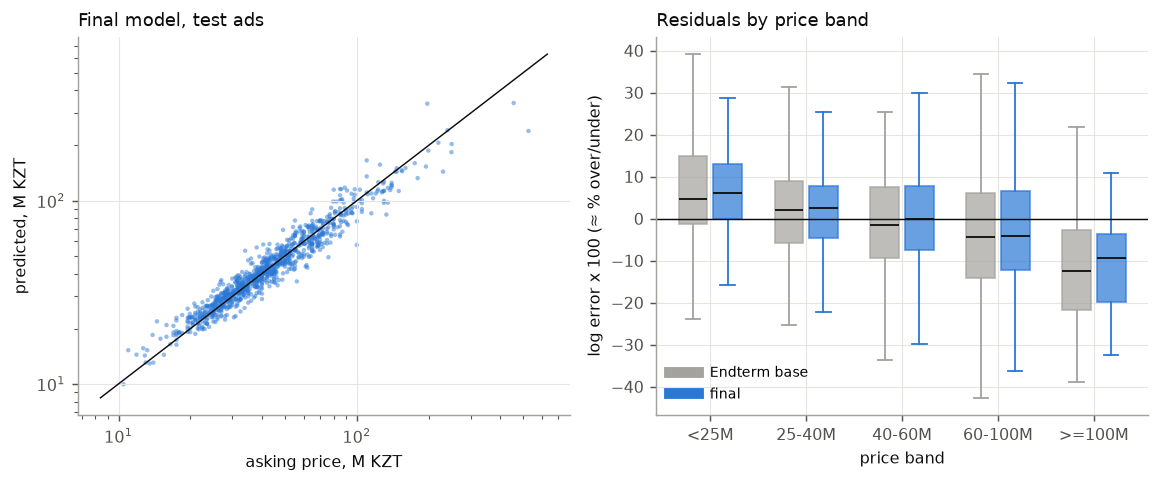

,id,price,pred_final,pred_base,log_error_final,seg_city,seg_price_band,seg_rooms,seg_photos,seg_text,seg_duplicate,seg_train_twin,abs_error_M,ape_pct
0,1015790107,5.250e+08,2.399e+08,2.454e+08,-0.783,Almaty,>=100M,4+,with photo embedding,description >=100 chars,unique ad,no train twin,285.052,54.296
1,1016128179,1.976e+08,3.380e+08,2.626e+08,0.537,Almaty,>=100M,4+,with photo embedding,description >=100 chars,unique ad,no train twin,140.431,71.075
2,1011662498,4.550e+08,3.409e+08,3.379e+08,-0.289,Almaty,>=100M,4+,no photos,description >=100 chars,unique ad,no train twin,114.100,25.077
3,1011271841,2.300e+08,1.439e+08,1.557e+08,-0.469,Almaty,>=100M,4+,with photo embedding,description >=100 chars,unique ad,no train twin,86.120,37.443
4,1013767426,2.495e+08,1.839e+08,1.908e+08,-0.305,Astana,>=100M,4+,with photo embedding,description >=100 chars,unique ad,no train twin,65.645,26.311
5,1015161077,1.100e+08,1.658e+08,1.706e+08,0.410,Astana,>=100M,4+,with photo embedding,description >=100 chars,unique ad,no train twin,55.793,50.721
6,1015437063,1.330e+08,8.392e+07,7.433e+07,-0.460,Astana,>=100M,3,with photo embedding,description >=100 chars,unique ad,no train twin,49.075,36.899
7,699146557,1.800e+08,1.327e+08,1.067e+08,-0.305,Almaty,>=100M,2,with photo embedding,description >=100 chars,unique ad,no train twin,47.301,26.278
8,1016149904,2.500e+08,2.037e+08,2.288e+08,-0.205,Almaty,>=100M,4+,with photo embedding,description >=100 chars,unique ad,no train twin,46.318,18.527
9,1014407661,1.000e+08,5.729e+07,6.028e+07,-0.557,Astana,>=100M,3,no photos,description >=100 chars,unique ad,no train twin,42.714,42.714


In [25]:
err = read_csv("final_eval/error_by_segment.csv", index_col=0)
if err is not None:
    display(err)
show_figure("final_eval/residuals.png", width=820)
worst = read_csv("final_eval/worst_cases.csv")
if worst is not None:
    display(worst.head(10))

**Reading.** The error grows with the price in absolute terms (MAE 2.1 M below 25 M, 28.9 M above 100 M), and in relative terms the 25–60 M bands are the best (MdAPE 6.7 and 7.8 %), the tails the worst (8.4 % below 25 M, 12.9 % above 100 M). The model still under-predicts the most expensive band (median log error −0.09) and over-predicts the cheapest (+0.06): a model of the log price shrinks extremes towards the mean when the tails have few ads. The final model is better than the base in every city, price band and room count except **4+ rooms** (MAE +0.84 M, interval crossing zero, 67 ads) and the band above 100 M (−0.17 M, interval ±4.5 M): the gain is in the bulk of the market. Of the 20 largest errors, 17 are flats asked above 100 M; these are the ads the trust layer marks with its widest intervals.

### 9.1 The app: one listing end to end
`app/gradio_app.py` (UI) runs on `app/predict.py`. For a typed-in listing it builds the final model's inputs from the form: OSM geo features from the coordinates, text flags and the USER-base embedding from the description, the CLIP embedding of up to three photos; raw ad-page fields and the photo track's tabular features cannot come from a form and stay missing (as for training ads without them), and the app says so. Around the estimate it shows the conformal 80 / 90 % interval, an interval-based verdict, SHAP reasons (for the HGB half of the blend), five comparable training ads, text red flags and the photo condition with a mismatch check. The card below was rendered by `scripts/make_app_example.py` for a hand-made listing (not a test ad).

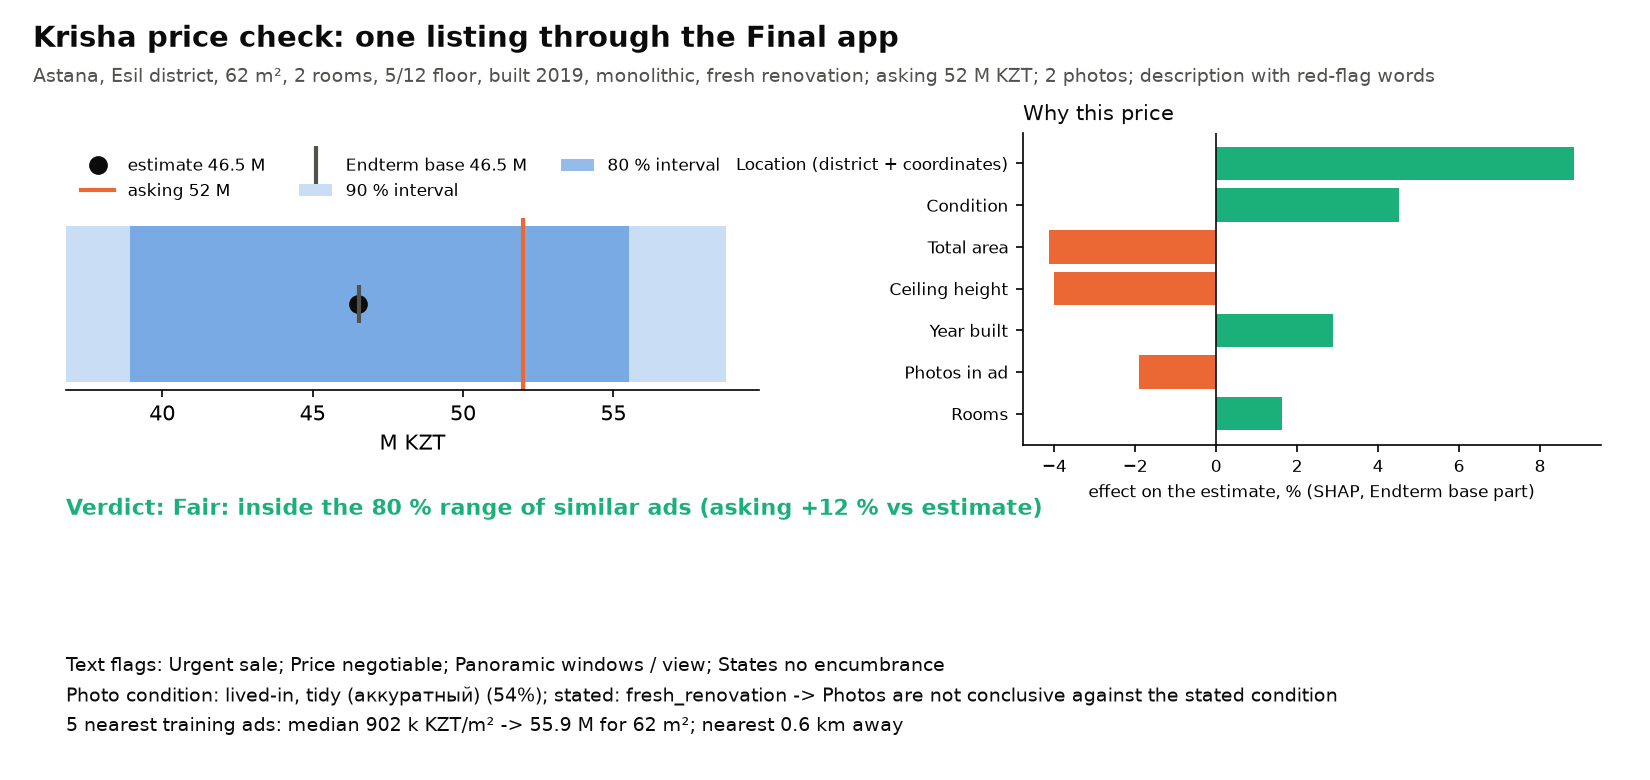

True

In [26]:
show_figure("final/app_example.png", width=900)

**Reading.** The final estimate (46.5 M) and the Endterm base agree for this ordinary flat; the asking price of 52 M is 12 % above the estimate but inside the 80 % interval, so the verdict is "fair", where the Endterm's 20 % rule would also not have fired. The reasons are the location (+9 %) and the stated fresh renovation (+5 %); the photos are not conclusive against the stated condition, and the description raises "urgent sale" and "price negotiable", which in the training ads go with asking prices 1–3 % below the estimate.

## 10. Limitations, why not deep reinforcement learning, and conclusions

**Limitations and biases.**
- **Asking prices, not sale prices.** krisha.kz shows what sellers ask; the deal price, often lower, is not public. The model learns the asking market, with its optimism, and "over-priced" means "asked above comparable asking prices".
- **One snapshot.** 4,815 ads from 4–8 October 2026 plus 1,507 from 8 November; seasonal effects and price trends beyond one month are not covered.
- **Coverage bias.** Ads with missing fields, few photos or short texts are more often cheap or agency-posted; the blocks help these ads least.
- **Five folds are a coarse ruler.** The rule rejects small but consistent gains (the text block improved every fold); with a larger dataset or repeated CV they might pass.
- **Labels for the photo model are seller-reported** and noisy; the mismatch flag shows how often they disagree with the pictures.
- **OSM completeness** varies between districts; a missing park in OSM looks like no park.
- **November hold-out at listing level only**: the ad pages (coordinates, description, photos) were blocked by the site's bot protection on 8 November, so the fused model could not be tested a month later, only a reduced model of the same family.
- **A reused test set.** The 963 saved test ads were scored at the Endterm and again here; no Final choice looked at them, but they are no longer a perfectly fresh sample.
- **The app sees less than the CV.** A form cannot supply the raw ad-page fields and the photo track's tabular features; the app leaves them missing (as for training ads without them), so its estimates for a typed-in flat have not been validated by CV in exactly that input pattern.
- **Whole-model, not per-block, certification.** The final model passes the rule as a whole; no single block passes it step by step.

**Why no deep reinforcement learning.** Reinforcement learning learns a *policy* from *rewards* for actions taken in an environment. Our data contain no actions and no outcomes: we see asking prices only, not whether or when a flat sold, at what price, or how long it stayed on the market (days-on-market is not shown and we have one snapshot, so we cannot follow an ad over time). A pricing agent would need exactly that reward (sold or not, time to sale, final price) and many interactions with buyers; without it, any "reward" we wrote would be the asking price itself, and RL would collapse into the regression we already have, with more variance. The right tool for "is this price fair" is supervised regression with calibrated uncertainty, which is what we built; RL would become relevant with longitudinal data (price changes and removal dates of the same ad), which is the first item of future work.

**Conclusions.**
1. The Endterm model is reproduced exactly (6.616 ± 0.353 M CV), and its CV is honest: duplicate ads are few (1.35 % of the test ads have a twin) and grouped folds change the score by much less than one SD.
2. Location, photos and text each contain price information the 24 fields miss (best CV gains -0.135, -0.190 and -0.280 M), but no single block passes the 0.354 M rule. Together, in a 50/50 blend of a multimodal network with the Endterm model, they do: CV 6.100 M on the repaired folds (base 6.723).
3. On the 963 saved test ads, scored once: MAE 5.80 M (Endterm 6.29; paired 95 % interval of the difference -0.80 to -0.16 M), MdAPE 7.82 % (Endterm 9.13 %). A month later, with the fields of a search card only, the October model loses ~0.35 pp of MdAPE: the drift is small.
4. The largest gain for the user is not a lower MAE but the trust layer: a calibrated 90 % interval, the reasons (SHAP), five real comparable ads and a flag whose threshold adapts to how well the model knows the flat.

## 11. Contributions and AI tools

**Rakhat Balgabekov** — the shared `krisha_ml` foundation and the reproduction of the Endterm, the leakage audit and grouped folds, the photo track (CLIP, probes, fine-tuning, Grad-CAM), the November scrape, the deliverable builders.
**Aitbek Kaiyrbekuly** — the location track (OSM features, raw ad-page fields), the text track (TF-IDF, transformers, red flags), the trust layer (conformal intervals, SHAP, comparables), the error analysis and the slides.
Both: the selection rule, the readings under every table and plot and the conclusions were discussed and written together; both can explain every part of the notebook.

**AI tools.** We used an AI coding assistant (Claude, via Claude Code) more heavily than in the Endterm, and we state it plainly. For the Final we ran several assistant sessions in parallel, one per track (leakage, location, photos, text, trust, integration), on a shared code contract (`CONTRACT.md`) with one CV harness and one fixed selection rule, so that no track could choose its own yardstick. The assistant wrote most of the code in `krisha_ml/`, `scripts/` and `app/`, ran the experiments on our machine, drafted the readings, the report and the slides from the outputs, and reviewed the tracks against each other (for example, the leakage review that corrected the rule threshold from 6.459 to 6.370 M). We chose the question and the data, set the selection rule and the one-time use of the test ads, decided what to keep, checked the numbers and the readings against the outputs, and are responsible for every claim; both of us can explain every part of the notebook.